# Machine Learning Analysis of the Effects of Tyre Characteristics and Weather Conditions on Formula 1 Performance

## Final Data Analysis and Machine Learning Results

This notebook presents the final analysis of Formula 1 lap performance using data collected from the OpenF1 API for the 2023, 2024, and 2025 seasons.

The analysis investigates relationships between tyre characteristics, weather conditions, and lap times. It also compares machine learning models using race-grouped cross-validation to assess their predictive performance on held-out races.

The notebook includes data summaries, visualisations, model comparisons, interpretation of findings, and methodological limitations.

In [29]:
# Work with our Formula 1 datasets
import pandas as pd
import numpy as np

# Create professional graphs and visualisations
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent appearance for our graphs
sns.set_theme(style="whitegrid")

### 1. Data Preparation and Overview

#### 1.1 Data Sources

This study uses Formula 1 lap-level data obtained from the OpenF1 API for the 2023, 2024, and 2025 seasons.

The dataset combines lap times with tyre compound information, estimated tyre age, and weather observations, including air temperature, track temperature, humidity, rainfall, wind speed, and atmospheric pressure.

A separate results file contains the performance of three regression algorithms—Linear Regression, Random Forest, and Gradient Boosting—evaluated using five-fold race-grouped cross-validation.

#### 1.2 Purpose of This Section

This section loads the prepared datasets and examines their structure, completeness, and suitability for subsequent visualisation and machine learning analysis.

In [30]:
# Load our cleaned Formula 1 lap dataset
f1_data = pd.read_csv("f1_2023_2025_model_ready.csv")

# Load the five-fold machine learning comparison results
cv_results = pd.read_csv("f1_model_cv_results.csv")

# Check that both files loaded correctly
print("F1 lap records:", len(f1_data))
print("Cross-validation folds:", len(cv_results))

# Display the saved model comparison
display(cv_results.head())

F1 lap records: 74508
Cross-validation folds: 5


,Fold,Linear Regression,Gradient Boosting,Random Forest,Gradient Boosting + Weather,Linear Regression + Weather
0,1,4.294032,4.642477,7.087061,4.190199,4.711897
1,2,6.313615,7.677373,8.659613,7.834347,6.384299
2,3,5.389884,6.316686,6.376069,8.133489,5.519389
3,4,5.296332,5.924757,7.774510,7.723393,5.892192
4,5,7.259224,7.447920,8.541575,8.320964,8.186301


#### 1.3 Dataset Structure and Initial Inspection

Before conducting the analysis, the prepared dataset is inspected to identify its available variables, data types, and overall dimensions.

This inspection helps establish which tyre characteristics, weather measurements, and lap-performance variables are available for visualisation and statistical analysis. It also provides an initial check that the expected data has been loaded successfully.

In [31]:
# Display the number of rows and columns in the dataset
print("Dataset dimensions:", f1_data.shape)

# Display the names of all available columns
print("\nAvailable columns:")
print(f1_data.columns.tolist())

# Display the first five records
print("\nFirst five records:")
display(f1_data.head())

Dataset dimensions: (74508, 34)

Available columns:
['date_start', 'driver_number', 'duration_sector_1', 'duration_sector_2', 'duration_sector_3', 'i1_speed', 'i2_speed', 'is_pit_out_lap', 'lap_duration', 'lap_number', 'meeting_key', 'segments_sector_1', 'segments_sector_2', 'segments_sector_3', 'session_key', 'st_speed', 'race_name', 'air_temperature', 'date', 'humidity', 'meeting_key_weather', 'pressure', 'rainfall', 'track_temperature', 'wind_direction', 'wind_speed', 'race_name_weather', 'weather_age_seconds', 'lap_id', 'compound', 'tyre_age', 'suspected_disruption', 'race_median', 'pace_ratio']

First five records:


,date_start,driver_number,duration_sector_1,duration_sector_2,duration_sector_3,i1_speed,i2_speed,is_pit_out_lap,lap_duration,lap_number,...,wind_direction,wind_speed,race_name_weather,weather_age_seconds,lap_id,compound,tyre_age,suspected_disruption,race_median,pace_ratio
0,2023-03-05 15:03:38.500000+00:00,1,33.103,42.414,23.842,232.0,231.0,False,99.359,1,...,0.0,0.6,Sakhir,50.952,0,SOFT,3.0,False,98.487,1.008854
1,2023-03-05 15:03:38.500000+00:00,21,38.329,46.835,25.179,217.0,226.0,False,110.343,1,...,0.0,0.6,Sakhir,50.952,1,SOFT,0.0,False,98.487,1.120381
2,2023-03-05 15:03:38.500000+00:00,10,38.115,46.780,25.135,214.0,234.0,False,110.030,1,...,0.0,0.6,Sakhir,50.952,2,SOFT,0.0,False,98.487,1.117203
3,2023-03-05 15:03:38.500000+00:00,18,36.263,44.143,24.609,223.0,250.0,False,105.015,1,...,0.0,0.6,Sakhir,50.952,3,SOFT,3.0,False,98.487,1.066283
4,2023-03-05 15:03:38.500000+00:00,20,37.770,46.858,25.043,235.0,241.0,False,109.671,1,...,0.0,0.6,Sakhir,50.952,4,HARD,0.0,False,98.487,1.113558


#### 1.4 Missing Data Assessment

Missing data can affect the reliability of statistical analysis and machine learning predictions. Therefore, the completeness of the main variables is assessed before further analysis.

The assessment focuses on lap duration, tyre compound, estimated tyre age, and the weather measurements used in this study. The number and percentage of missing observations are calculated for each variable.

This check also helps distinguish the complete prepared dataset from the subset of observations suitable for machine learning.

In [32]:
# Select the main variables used in our research
analysis_columns = [
    "lap_duration",
    "compound",
    "tyre_age",
    "air_temperature",
    "track_temperature",
    "humidity",
    "rainfall",
    "wind_speed",
    "pressure"
]

# Count missing values in each variable
missing_counts = f1_data[analysis_columns].isna().sum()

# Calculate the percentage of missing values
missing_percentages = (
    missing_counts / len(f1_data) * 100
).round(2)

# Combine the results into a readable table
missing_summary = pd.DataFrame({
    "Missing Values": missing_counts,
    "Missing (%)": missing_percentages
})

# Display the missing-data summary
display(missing_summary)

,Missing Values,Missing (%)
lap_duration,0,0.00
compound,0,0.00
tyre_age,0,0.00
air_temperature,19,0.03
track_temperature,19,0.03
humidity,19,0.03
rainfall,19,0.03
wind_speed,19,0.03
pressure,19,0.03


#### 1.5 Interpretation of Missing Data

The missing-data assessment indicates that the prepared dataset is highly complete. No missing observations were identified for lap duration, tyre compound, or estimated tyre age.

Each of the six weather variables contained 19 missing observations, representing approximately 0.03% of the 74,508 lap records.

These missing weather measurements affect the same 19 laps, leaving 74,489 observations with complete values across all nine variables assessed. Complete-case filtering was therefore applied when preparing the machine learning inputs that included weather variables.

The small proportion of missing weather observations suggests that data completeness is unlikely to be a major limitation of the analysis. However, completeness does not necessarily guarantee measurement accuracy, and other limitations relating to weather-data alignment and estimated tyre age remain relevant.

### 2. Exploratory Data Analysis

#### 2.1 Distribution of Tyre Compounds

Tyre compound selection is an important consideration in Formula 1 race strategy and performance.

This section examines the distribution of tyre compounds within the prepared dataset. Understanding the number of observations associated with each compound is important because unequal representation may influence subsequent statistical analysis and machine learning performance.

The distribution includes dry-weather compounds (SOFT, MEDIUM, and HARD) and wet-weather compounds (INTERMEDIATE and WET).

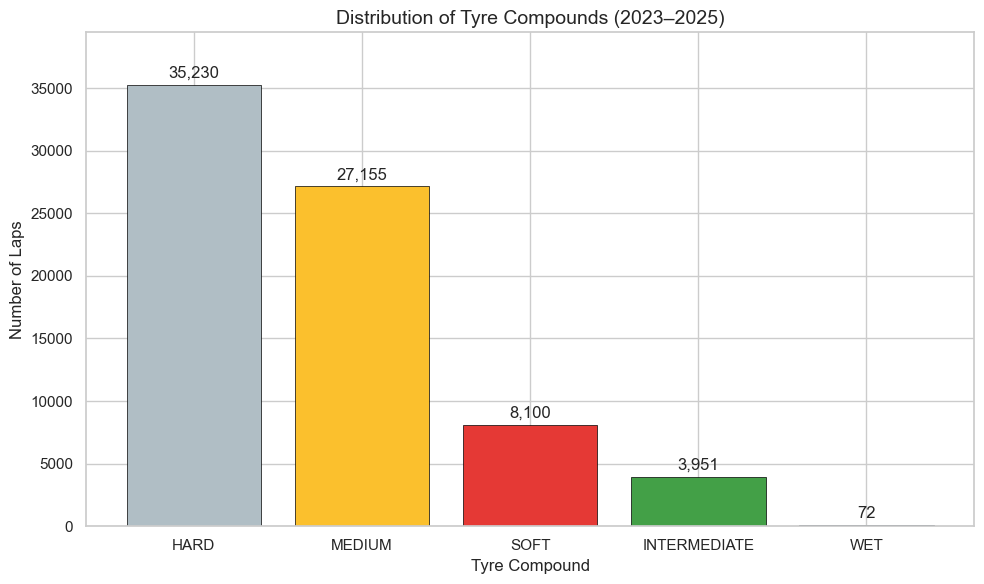

compound
HARD            35230
MEDIUM          27155
SOFT             8100
INTERMEDIATE     3951
WET                72
Name: count, dtype: int64

In [33]:
# Count the laps recorded for each tyre compound
compound_counts = f1_data["compound"].value_counts()

# Use the familiar Formula 1 tyre colours
compound_colours = {
    "SOFT": "#E53935",
    "MEDIUM": "#FBC02D",
    "HARD": "#B0BEC5",
    "INTERMEDIATE": "#43A047",
    "WET": "#1E88E5"
}

# Match the colours to the compounds in our dataset
bar_colours = [
    compound_colours.get(compound, "#888888")
    for compound in compound_counts.index
]

# Create the graph
plt.figure(figsize=(10, 6))

bars = plt.bar(
    compound_counts.index,
    compound_counts.values,
    color=bar_colours,
    edgecolor="black",
    linewidth=0.5
)

# Add a title and axis labels
plt.title("Distribution of Tyre Compounds (2023–2025)", fontsize=14)
plt.xlabel("Tyre Compound")
plt.ylabel("Number of Laps")

# Display the exact lap count above each bar
plt.bar_label(bars, labels=[f"{count:,}" for count in compound_counts.values], padding=3)

# Leave space above the bars for the labels
plt.ylim(0, compound_counts.max() * 1.12)

# Improve the layout and show the graph
plt.tight_layout()
plt.show()

# Display the counts for our dissertation interpretation
display(compound_counts)

#### 2.2 Interpretation of Tyre Compound Distribution

The tyre compound distribution shows that HARD tyres account for the largest proportion of observations, with 35,230 laps (47.28%), followed by MEDIUM tyres with 27,155 laps (36.45%). SOFT tyres account for 8,100 laps (10.87%), while INTERMEDIATE tyres represent 3,951 laps (5.30%).

WET tyres are substantially underrepresented, with only 72 observations (approximately 0.10% of the dataset).

Together, HARD and MEDIUM tyres account for approximately 83.73% of the recorded laps, indicating that the dataset is dominated by these two compounds.

This imbalance is important for machine learning because models have considerably fewer examples from which to learn patterns associated with wet-weather tyre compounds. Consequently, predictions involving WET tyres should be interpreted cautiously.

The distribution describes the frequency of tyre compounds within the prepared dataset; it does not establish that one compound produces better lap-time performance than another.

#### 2.3 Lap Duration by Tyre Compound

This analysis examines the distribution of recorded lap durations across the five tyre compounds.

A box plot is used to compare median lap durations, variability, and differences between compounds. This provides an initial descriptive view of how lap performance varies with tyre selection.

However, lap durations are also influenced by circuit layout, weather, fuel load, traffic, driver behaviour, and race interruptions. Therefore, differences observed between compounds should not be interpreted as direct causal effects of tyre choice.

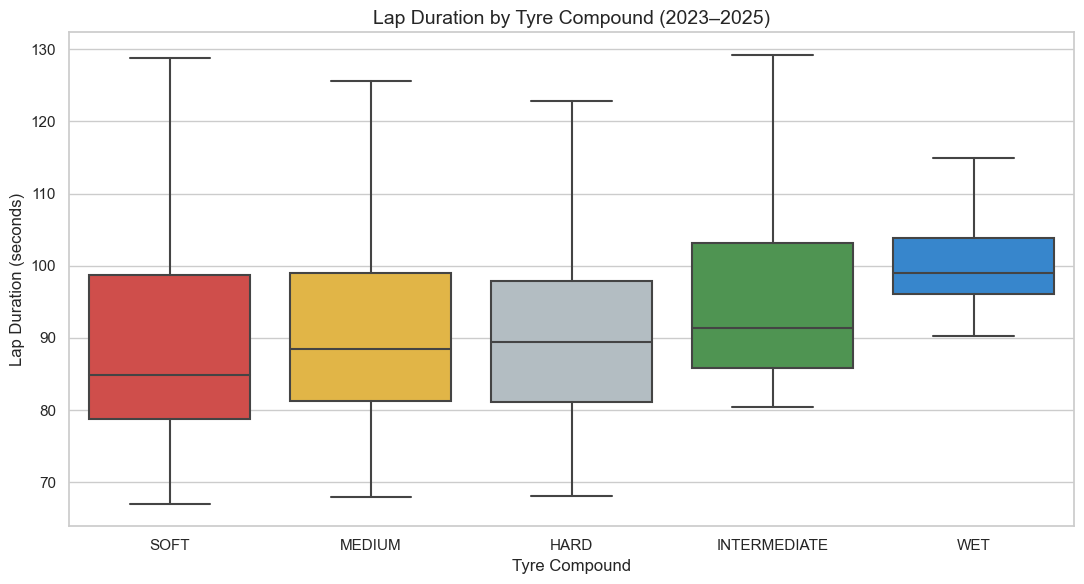

Median lap duration by tyre compound (seconds):


compound
SOFT            84.92
MEDIUM          88.45
HARD            89.42
INTERMEDIATE    91.43
WET             99.02
Name: lap_duration, dtype: float64

In [34]:
# Set the order of tyre compounds on the graph
compound_order = [
    "SOFT", "MEDIUM", "HARD", "INTERMEDIATE", "WET"
]

# Use the familiar Formula 1 tyre colours
compound_colours = {
    "SOFT": "#E53935",
    "MEDIUM": "#FBC02D",
    "HARD": "#B0BEC5",
    "INTERMEDIATE": "#43A047",
    "WET": "#1E88E5"
}

# Create a figure for comparing lap durations
plt.figure(figsize=(11, 6))

# Draw a box plot without individual outlier markers
sns.boxplot(
    data=f1_data,
    x="compound",
    y="lap_duration",
    order=compound_order,
    palette=compound_colours,
    showfliers=False
)

# Add a title and axis labels
plt.title("Lap Duration by Tyre Compound (2023–2025)", fontsize=14)
plt.xlabel("Tyre Compound")
plt.ylabel("Lap Duration (seconds)")

# Improve the layout and display the graph
plt.tight_layout()
plt.show()

# Calculate the median lap duration for each compound
compound_medians = (
    f1_data.groupby("compound")["lap_duration"]
    .median()
    .reindex(compound_order)
    .round(2)
)

# Display the exact medians for our interpretation
print("Median lap duration by tyre compound (seconds):")
display(compound_medians)

#### 2.4 Interpretation of Lap Duration by Tyre Compound

The descriptive analysis shows differences in median lap duration across the five tyre compounds.

SOFT tyres recorded the lowest median lap duration at 84.92 seconds, followed by MEDIUM tyres at 88.45 seconds and HARD tyres at 89.42 seconds. INTERMEDIATE tyres had a median of 91.43 seconds, while WET tyres recorded the highest median at 99.02 seconds.

Although these results indicate an association between tyre compound and recorded lap duration, they should not be interpreted as a direct ranking of tyre performance.

The dataset combines observations from multiple Formula 1 circuits, which differ substantially in layout and lap length. Furthermore, tyre selection is influenced by track conditions and race strategy. INTERMEDIATE and WET tyres are generally used in conditions that differ from those associated with dry-weather compounds.

The WET category also contains only 72 observations, making its descriptive statistics less representative than those of the more frequently used compounds.

Consequently, the observed differences provide useful exploratory evidence but do not establish that tyre compound alone determines lap performance. Further analysis that accounts for circuit characteristics and other relevant variables is necessary to interpret these relationships more reliably.

#### 2.5 Race-Relative Lap Performance by Tyre Compound

Direct comparisons of lap duration across different Formula 1 circuits can be misleading because circuit layouts and lap lengths vary considerably.

To provide a more comparable descriptive measure, this analysis uses the `pace_ratio` variable, calculated as the recorded lap duration divided by the median lap duration for the corresponding race.

A pace ratio of 1.00 represents the race median, while values above 1.00 indicate laps slower than that reference.

This normalisation reduces the influence of differences in typical lap duration between races. However, it does not eliminate the effects of race conditions, driver differences, tyre strategy, or interruptions.

In [35]:
# Define the order of tyre compounds
compound_order = [
    "SOFT", "MEDIUM", "HARD", "INTERMEDIATE", "WET"
]

# Calculate the median race-relative pace for each compound
pace_medians = (
    f1_data.groupby("compound")["pace_ratio"]
    .median()
    .reindex(compound_order)
)

# Display the results as a readable table
pace_summary = pd.DataFrame({
    "Median Pace Ratio": pace_medians.round(4),
    "Median Difference from Race Median (%)": (
        (pace_medians - 1) * 100
    ).round(2)
})

# Display the summary
display(pace_summary)

,Median Pace Ratio,Median Difference from Race Median (%)
compound,,
SOFT,1.0006,0.06
MEDIUM,1.0025,0.25
HARD,0.9972,-0.28
INTERMEDIATE,1.0210,2.10
WET,1.2375,23.75


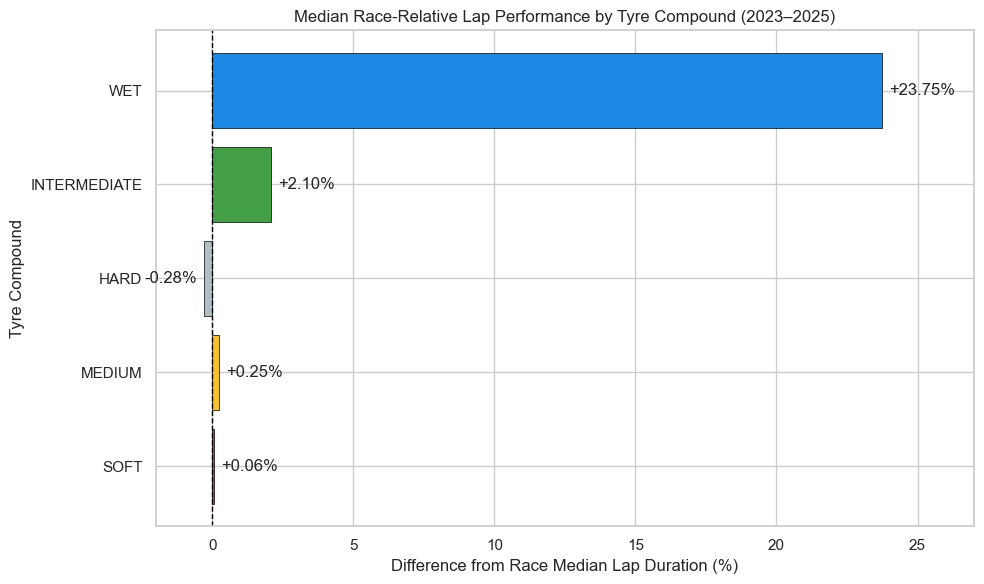

In [36]:
# Define the colours used for each Formula 1 tyre compound
compound_colours = {
    "SOFT": "#E53935",
    "MEDIUM": "#FBC02D",
    "HARD": "#B0BEC5",
    "INTERMEDIATE": "#43A047",
    "WET": "#1E88E5"
}

# Calculate the median percentage difference for each compound
pace_percentages = (pace_medians - 1) * 100

# Match the bar colours to the tyre compounds
bar_colours = [
    compound_colours[compound]
    for compound in pace_percentages.index
]

# Create a horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    pace_percentages.index,
    pace_percentages.values,
    color=bar_colours,
    edgecolor="black",
    linewidth=0.5
)

# Mark the race median as our reference point
ax.axvline(
    x=0,
    color="black",
    linestyle="--",
    linewidth=1
)

# Add percentage labels to the bars
for bar, value in zip(bars, pace_percentages.values):
    ax.annotate(
        f"{value:+.2f}%",
        xy=(value, bar.get_y() + bar.get_height() / 2),
        xytext=(5 if value >= 0 else -5, 0),
        textcoords="offset points",
        ha="left" if value >= 0 else "right",
        va="center"
    )

# Add descriptive labels
ax.set_title("Median Race-Relative Lap Performance by Tyre Compound (2023–2025)")
ax.set_xlabel("Difference from Race Median Lap Duration (%)")
ax.set_ylabel("Tyre Compound")

# Leave room for the percentage labels
ax.set_xlim(-2, 27)

# Display the graph
plt.tight_layout()
plt.show()

#### 2.6 Interpretation of Race-Relative Lap Performance

The race-relative analysis provides a different perspective from the comparison of raw lap durations.

HARD tyres recorded the lowest median pace ratio, corresponding to a lap duration approximately 0.28% below the median for the associated race. SOFT and MEDIUM tyres recorded median differences of approximately +0.06% and +0.25%, respectively.

These differences are relatively small, suggesting that the typical race-relative lap durations observed for the three dry-weather compounds are close to their corresponding race medians.

INTERMEDIATE tyres recorded a median difference of +2.10%, while WET tyres showed a substantially larger difference of +23.75%.

The larger values for wet-weather compounds should be interpreted in the context of their operating conditions. Wet-weather tyres are generally selected when track conditions differ considerably from those experienced during dry-weather running. Slower lap durations may therefore reflect reduced grip, weather conditions, race interruptions, and other factors rather than tyre compound alone.

Furthermore, the WET category contains only 72 observations, limiting the reliability and generalisability of comparisons involving this compound.

Although normalising lap durations by race median helps account for differences in typical lap times between races, it does not fully control for driver ability, fuel load, traffic, race strategy, or changing track conditions.

Therefore, these results describe associations within the dataset rather than demonstrating that any particular tyre compound directly causes faster or slower lap times.

#### 2.7 Distribution of Estimated Tyre Age

Tyre age is an important variable in Formula 1 performance analysis because tyre condition can change as laps accumulate during a stint.

This study uses an estimated tyre-age variable derived from the available stint information. The variable serves as a proxy for tyre usage rather than a direct measurement of physical tyre wear or degradation.

Examining its distribution helps identify the range of tyre ages represented in the dataset and whether observations are concentrated at particular stages of a stint.

This analysis is descriptive and does not, by itself, establish how tyre age affects lap performance.

Estimated tyre age summary:


count    74508.000000
mean        14.201965
std         10.521459
min          0.000000
25%          6.000000
50%         12.000000
75%         20.000000
max         78.000000
Name: tyre_age, dtype: float64

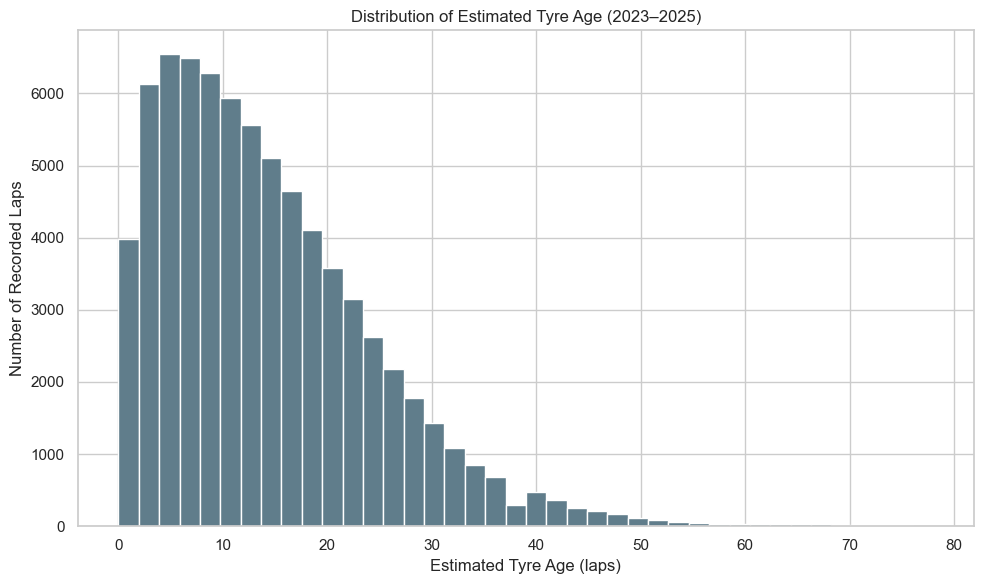

In [37]:
# Calculate descriptive statistics for estimated tyre age
tyre_age_summary = f1_data["tyre_age"].describe()

# Display the summary statistics
print("Estimated tyre age summary:")
display(tyre_age_summary)

# Create a histogram of estimated tyre age
plt.figure(figsize=(10, 6))

plt.hist(
    f1_data["tyre_age"].dropna(),
    bins=40,
    color="#607D8B",
    edgecolor="white"
)

# Add a title and axis labels
plt.title("Distribution of Estimated Tyre Age (2023–2025)")
plt.xlabel("Estimated Tyre Age (laps)")
plt.ylabel("Number of Recorded Laps")

# Improve the layout and display the graph
plt.tight_layout()
plt.show()

#### 2.8 Interpretation of Estimated Tyre Age

The descriptive analysis of estimated tyre age includes 74,508 observations, with no missing values.

The mean estimated tyre age is approximately 14.20 laps, while the median is 12 laps. The standard deviation is approximately 10.52 laps, indicating considerable variation in estimated tyre usage across the dataset.

The first and third quartiles are 6 and 20 laps, respectively. This indicates that the middle 50% of observations fall within this range.

Estimated tyre age ranges from 0 to 78 laps, showing that the dataset includes observations associated with both relatively fresh and substantially older tyres.

The mean exceeding the median suggests that larger tyre-age values influence the average, consistent with a distribution extending towards higher values.

Importantly, estimated tyre age is a proxy derived from stint information and should not be interpreted as a direct measurement of physical tyre degradation. Its accuracy may also be affected by limitations in the underlying stint records.

These findings establish the distribution of the tyre-age variable but do not determine whether increasing tyre age is associated with slower lap performance. That relationship is examined in the subsequent analysis.

#### 2.9 Relationship Between Estimated Tyre Age and Race-Relative Lap Performance

This analysis investigates the association between estimated tyre age and race-relative lap duration.

Lap performance is represented by the pace ratio, which compares each lap's duration with the median lap duration for its corresponding race.

Median pace ratios are calculated for each estimated tyre age to examine whether lap performance changes as tyre usage increases.

The analysis is exploratory. Changes in lap duration may reflect tyre degradation, but they may also be influenced by fuel consumption, circuit characteristics, weather, traffic, race strategy, and interruptions. Therefore, any observed relationship should not be interpreted as a direct causal effect of tyre age.

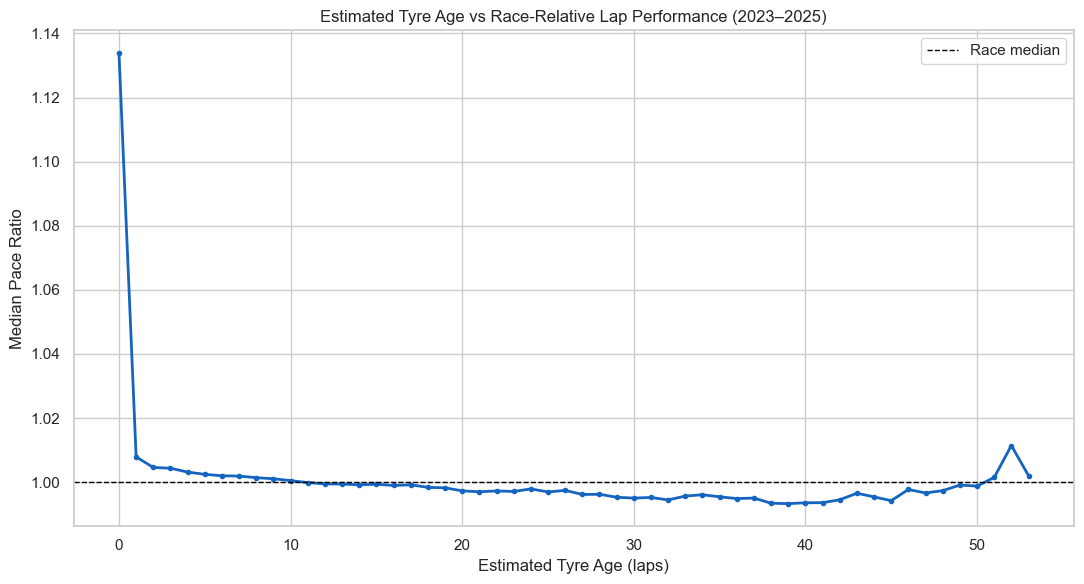

Tyre-age values plotted: 54
Oldest tyre age plotted: 53.0
Median pace ratio at tyre age 0:


,pace_ratio,lap_count
0,1.133908,1309


In [38]:
# Calculate the median pace ratio for each estimated tyre age
tyre_age_pace = (
    f1_data.groupby("tyre_age")["pace_ratio"]
    .median()
    .reset_index()
)

# Count how many laps contribute to each tyre-age value
tyre_age_counts = (
    f1_data.groupby("tyre_age")
    .size()
    .reset_index(name="lap_count")
)

# Combine the median pace ratios with their lap counts
tyre_age_pace = tyre_age_pace.merge(
    tyre_age_counts,
    on="tyre_age"
)

# Keep tyre ages with at least 30 observations
# This avoids drawing conclusions from very small groups
tyre_age_pace_plot = tyre_age_pace[
    tyre_age_pace["lap_count"] >= 30
].copy()

# Create the line graph
plt.figure(figsize=(11, 6))

plt.plot(
    tyre_age_pace_plot["tyre_age"],
    tyre_age_pace_plot["pace_ratio"],
    color="#1565C0",
    linewidth=2,
    marker="o",
    markersize=3
)

# Add the race-median reference line
plt.axhline(
    y=1.0,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Race median"
)

# Add a title and axis labels
plt.title("Estimated Tyre Age vs Race-Relative Lap Performance (2023–2025)")
plt.xlabel("Estimated Tyre Age (laps)")
plt.ylabel("Median Pace Ratio")
plt.legend()

# Improve the layout and display the graph
plt.tight_layout()
plt.show()

# Display a few summary values
print("Tyre-age values plotted:", len(tyre_age_pace_plot))
print("Oldest tyre age plotted:", tyre_age_pace_plot["tyre_age"].max())
print("Median pace ratio at tyre age 0:")
display(tyre_age_pace.loc[tyre_age_pace["tyre_age"] == 0, ["pace_ratio", "lap_count"]])

In [39]:
# Select laps with an estimated tyre age of zero
age_zero_laps = f1_data[f1_data["tyre_age"] == 0]

# Count the recorded lap numbers for these observations
lap_number_counts = age_zero_laps["lap_number"].value_counts()

# Display the ten most common lap numbers
print("Most common lap numbers for tyre age 0:")
display(lap_number_counts.head(10))

# Calculate how many tyre-age-zero records are race lap 1
first_lap_count = (age_zero_laps["lap_number"] == 1).sum()

# Display the percentage
print(
    "Percentage occurring on race lap 1:",
    round(first_lap_count / len(age_zero_laps) * 100, 2),
    "%"
)

Most common lap numbers for tyre age 0:


lap_number
1     1071
2       20
33      19
44      18
54      13
25      13
12      12
53       8
7        6
47       6
Name: count, dtype: int64

Percentage occurring on race lap 1: 81.82 %


#### 2.10 Interpretation of Estimated Tyre Age and Race-Relative Performance

The relationship between estimated tyre age and race-relative lap duration is not characterised by a consistent increase in lap time as tyre age increases.

At an estimated tyre age of zero, the median pace ratio is approximately 1.134, indicating a median lap duration approximately 13.4% above the corresponding race median. The median pace ratio subsequently decreases towards 1.00 during the early stages of tyre usage.

Further investigation identified 1,309 observations with an estimated tyre age of zero. Of these, 1,071 observations (81.82%) occurred on the first lap of a race.

This concentration suggests that race-start conditions are an important contributor to the unusually high pace ratio observed at tyre age zero. First-lap durations may be affected by standing starts, acceleration, traffic, and changes in track position.

Beyond the earliest tyre ages, the median pace ratio remains relatively close to 1.00 across much of the observed range, without demonstrating a simple, consistently increasing trend.

However, this pattern should not be interpreted as evidence that tyre degradation does not occur. Decreasing fuel load, changing track conditions, driver behaviour, tyre strategy, and race interruptions may obscure the relationship between tyre usage and lap performance.

Additionally, the tyre-age variable is estimated from stint information and does not directly measure physical tyre wear.

The visualisation includes only tyre-age values represented by at least 30 observations, limiting the influence of sparsely represented ages on the displayed trend.

Overall, the findings indicate that estimated tyre age alone does not provide a straightforward explanation of race-relative lap performance. More controlled comparisons are required to distinguish tyre-related effects from other influences on lap duration.

### 3. Weather Conditions and Formula 1 Performance

#### 3.1 Descriptive Analysis of Weather Conditions

Weather conditions can influence Formula 1 performance through changes in tyre temperature, grip, aerodynamic behaviour, and track conditions.

This section examines six weather variables included in the prepared dataset: air temperature, track temperature, humidity, rainfall, wind speed, and atmospheric pressure.

Descriptive statistics are used to identify the range and variability of the recorded weather conditions before investigating their relationships with lap performance.

The weather observations were matched to lap records using timestamps. Consequently, these measurements represent the available weather observations associated with each lap rather than continuous measurements throughout the entire lap.

In [40]:
# Select the six weather variables used in our research
weather_columns = [
    "air_temperature",
    "track_temperature",
    "humidity",
    "rainfall",
    "wind_speed",
    "pressure"
]

# Calculate descriptive statistics for each weather variable
weather_summary = f1_data[weather_columns].describe()

# Round the results to two decimal places
weather_summary = weather_summary.round(2)

# Display the weather summary table
print("Weather conditions summary (2023–2025):")
display(weather_summary)

Weather conditions summary (2023–2025):


,air_temperature,track_temperature,humidity,rainfall,wind_speed,pressure
count,74489.00,74489.00,74489.00,74489.00,74489.00,74489.00
mean,23.81,35.16,53.00,0.03,1.75,986.01
std,4.67,8.87,16.18,0.18,0.99,53.70
min,14.20,16.70,17.00,0.00,0.00,778.50
25%,19.70,29.40,42.00,0.00,1.10,987.90
50%,24.10,34.10,55.00,0.00,1.50,1007.70
75%,27.30,42.80,64.00,0.00,2.20,1013.50
max,33.90,52.70,92.00,1.00,6.90,1021.90


#### 3.2 Interpretation of Weather Conditions

The descriptive analysis includes 74,489 lap-associated observations with complete weather measurements.

The mean air temperature was 23.81°C, with recorded values ranging from 14.20°C to 33.90°C. Track temperatures were generally higher, with a mean of 35.16°C and a range from 16.70°C to 52.70°C.

Track temperature also displayed greater variability than air temperature, with standard deviations of 8.87°C and 4.67°C, respectively. This variation is relevant because track-surface conditions may influence tyre behaviour and lap performance.

Relative humidity ranged from 17% to 92%, with a mean of 53%. Recorded wind speeds ranged from 0.00 to 6.90 in the units supplied by the data source.

The rainfall indicator had a median of zero and a mean of approximately 0.03, suggesting that observations indicating rainfall were relatively uncommon in the prepared dataset.

Atmospheric pressure ranged from 778.50 to 1021.90 in the units supplied by the data source. Its comparatively wide range may reflect differences in circuit altitude and local atmospheric conditions, although this requires further investigation.

These statistics demonstrate that the dataset includes a broad range of weather conditions across the three Formula 1 seasons.

However, the results describe weather observations associated with individual laps. They do not establish that any particular weather variable independently caused changes in lap performance. In addition, repeated weather measurements across nearby laps mean that the observations are not necessarily statistically independent.

#### 3.3 Relationship Between Air Temperature and Track Temperature

Air temperature and track temperature represent different aspects of the environmental conditions experienced during a Formula 1 race.

Track temperature may differ substantially from air temperature because the racing surface absorbs and releases heat in response to sunlight, cloud cover, and other environmental factors.

This analysis uses a scatter plot to examine the relationship between the two temperature measurements and identify whether higher air temperatures are generally associated with higher track temperatures.

The analysis is descriptive and does not establish a causal relationship between the variables.

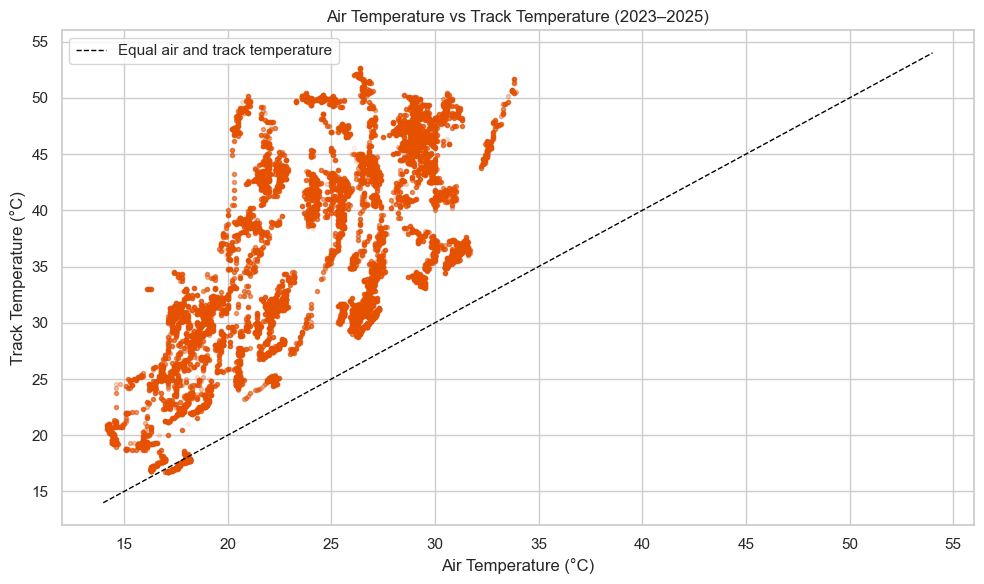

Pearson correlation between air and track temperature: 0.696


In [41]:
# Select laps with both temperature measurements available
temperature_data = f1_data[
    ["air_temperature", "track_temperature"]
].dropna()

# Create a scatter plot of air and track temperatures
plt.figure(figsize=(10, 6))

plt.scatter(
    temperature_data["air_temperature"],
    temperature_data["track_temperature"],
    alpha=0.08,
    s=8,
    color="#E65100"
)

# Add a reference line where track and air temperatures are equal
plt.plot(
    [14, 54],
    [14, 54],
    color="black",
    linestyle="--",
    linewidth=1,
    label="Equal air and track temperature"
)

# Add a title and axis labels
plt.title("Air Temperature vs Track Temperature (2023–2025)")
plt.xlabel("Air Temperature (°C)")
plt.ylabel("Track Temperature (°C)")
plt.legend()

# Improve the layout and display the graph
plt.tight_layout()
plt.show()

# Calculate the correlation between the two measurements
temperature_correlation = temperature_data[
    "air_temperature"
].corr(temperature_data["track_temperature"])

# Display the correlation coefficient
print(
    "Pearson correlation between air and track temperature:",
    round(temperature_correlation, 3)
)

#### 3.4 Interpretation of Air and Track Temperature

The scatter plot demonstrates a positive association between air temperature and track temperature across the Formula 1 observations recorded between 2023 and 2025.

The Pearson correlation coefficient was 0.696, indicating a moderately strong positive linear relationship between the two variables. This suggests that higher air temperatures are generally associated with higher track temperatures.

Most observations appear above the line representing equal air and track temperatures, indicating that track temperatures were generally higher than the corresponding air temperatures.

However, the scatter plot also shows substantial variation in track temperature at similar air temperatures. This suggests that air temperature alone does not fully account for differences in track-surface temperature.

Other environmental factors, including solar radiation, cloud cover, and surface characteristics, may contribute to these differences, although their individual effects were not established by this analysis.

The correlation should not be interpreted as evidence of causation. Furthermore, multiple laps may share the same weather observation, meaning the data points are not necessarily statistically independent.

These findings are relevant to the subsequent machine learning analysis because air temperature and track temperature contain overlapping information. Their correlation may influence how predictive models use and interpret these variables.

Overall, the results establish a clear association between the two temperature measurements but do not determine their individual contributions to lap-time performance.

#### 3.5 Relationship Between Track Temperature and Race-Relative Lap Performance

Track temperature is a potentially important factor in Formula 1 performance because it can influence tyre operating conditions and available grip.

This analysis investigates the association between recorded track temperature and race-relative lap duration.

Track temperatures are grouped into 2°C intervals, and the median pace ratio is calculated for each interval. Grouping observations in this way provides a clearer descriptive overview of the relationship.

The analysis is exploratory and does not isolate the effect of track temperature from other influences, including circuit characteristics, tyre selection, fuel load, driver behaviour, and race conditions.

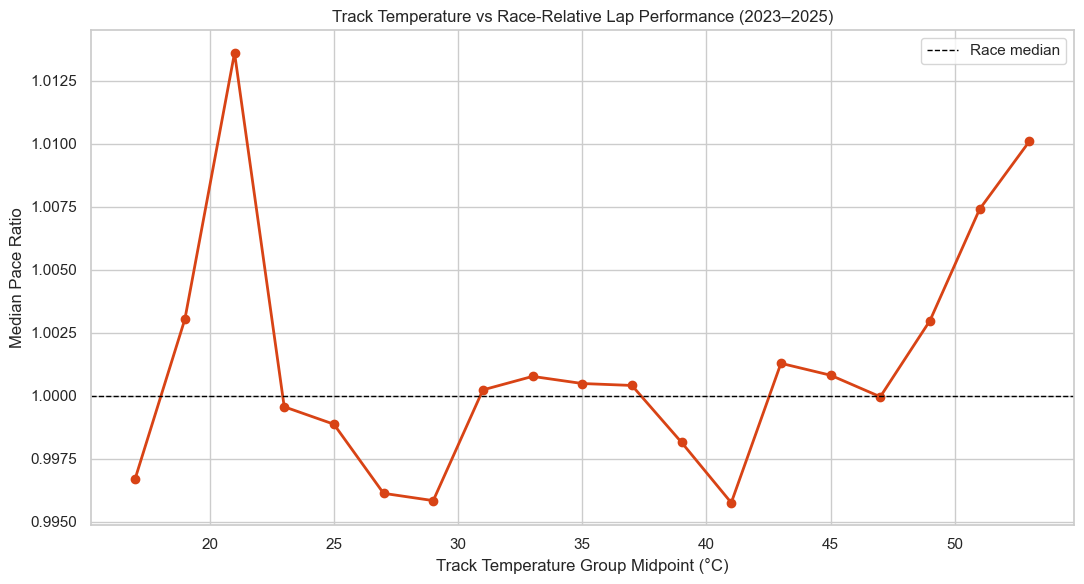

Temperature groups plotted: 19
Lowest median pace ratio: 0.9958
Highest median pace ratio: 1.0136


In [42]:
# Select laps with valid track temperature and pace ratio
track_pace_data = f1_data[
    ["track_temperature", "pace_ratio"]
].dropna().copy()

# Group track temperatures into 2°C intervals
track_pace_data["temperature_group"] = (
    track_pace_data["track_temperature"] // 2 * 2
)

# Calculate median pace and lap count for each temperature group
track_pace_summary = (
    track_pace_data.groupby("temperature_group")
    .agg(
        median_pace_ratio=("pace_ratio", "median"),
        lap_count=("pace_ratio", "size")
    )
    .reset_index()
)

# Keep temperature groups containing at least 100 laps
track_pace_plot = track_pace_summary[
    track_pace_summary["lap_count"] >= 100
].copy()

# Create the line graph
plt.figure(figsize=(11, 6))

plt.plot(
    track_pace_plot["temperature_group"] + 1,
    track_pace_plot["median_pace_ratio"],
    marker="o",
    linewidth=2,
    color="#D84315"
)

# Mark the race-median reference
plt.axhline(
    1.0,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Race median"
)

# Add a title and axis labels
plt.title("Track Temperature vs Race-Relative Lap Performance (2023–2025)")
plt.xlabel("Track Temperature Group Midpoint (°C)")
plt.ylabel("Median Pace Ratio")
plt.legend()

# Improve spacing and display the graph
plt.tight_layout()
plt.show()

# Display the number of temperature groups included
print("Temperature groups plotted:", len(track_pace_plot))

# Display the lowest and highest median pace ratios
print(
    "Lowest median pace ratio:",
    round(track_pace_plot["median_pace_ratio"].min(), 4)
)

print(
    "Highest median pace ratio:",
    round(track_pace_plot["median_pace_ratio"].max(), 4)
)

#### 3.6 Interpretation of Track Temperature and Race-Relative Lap Performance

The analysis examined median race-relative lap duration across 19 track-temperature groups, using 2°C intervals with at least 100 observations per group.

The median pace ratios ranged from approximately 0.9958 to 1.0136. This corresponds to differences of approximately −0.42% to +1.36% relative to the associated race medians.

The graph shows fluctuations in median pace ratio across the observed temperature range rather than a consistent linear increase or decrease.

Some temperature groups, particularly near 21°C and at the highest observed temperatures, display higher median pace ratios. However, these patterns do not establish that track temperature independently causes slower lap performance.

Track temperature varies alongside other factors, including circuit location, weather conditions, tyre selection, race strategy, and changes in track conditions. These factors may influence the observed relationships.

Furthermore, grouping observations by temperature does not account for differences between drivers or fully isolate within-race changes in lap performance.

The findings therefore suggest that the relationship between track temperature and race-relative lap duration is complex and cannot be adequately explained by temperature alone.

This supports the need to investigate weather variables alongside tyre characteristics and circuit information in the subsequent machine learning analysis.

#### 3.7 Distribution of Recorded Rainfall Conditions

Rainfall is an important environmental variable in Formula 1 because wet track conditions can influence grip, tyre selection, and lap performance.

This analysis first examines the distribution of the recorded rainfall indicator to determine how frequently laps are associated with rainfall observations.

The rainfall variable is treated as an indicator of recorded rainfall rather than a measurement of rainfall intensity. Furthermore, a rainfall value of zero does not necessarily indicate a completely dry racing surface, as the track may remain wet after rainfall has stopped.

Understanding the representation of rainfall conditions is necessary before comparing lap performance across different weather conditions.

In [43]:
# Count the number of laps associated with each rainfall value
rainfall_counts = (
    f1_data["rainfall"]
    .value_counts(dropna=False)
    .sort_index()
)

# Calculate the percentage of all lap records
rainfall_percentages = (
    rainfall_counts / len(f1_data) * 100
).round(2)

# Combine the counts and percentages into a table
rainfall_summary = pd.DataFrame({
    "Lap Count": rainfall_counts,
    "Percentage (%)": rainfall_percentages
})

# Display the rainfall distribution
print("Distribution of recorded rainfall conditions:")
display(rainfall_summary)

Distribution of recorded rainfall conditions:


,Lap Count,Percentage (%)
rainfall,,
0.0,72034,96.68
1.0,2455,3.29
NaN,19,0.03


#### 3.8 Interpretation of Recorded Rainfall Conditions

The rainfall distribution indicates that most lap observations in the prepared dataset were associated with periods when rainfall was not recorded.

Of the 74,508 lap records, 72,034 observations (96.68%) had a rainfall indicator of zero, while 2,455 observations (3.29%) had a rainfall indicator of one. A further 19 observations (0.03%) contained missing rainfall information.

These findings demonstrate a substantial imbalance between observations associated with recorded rainfall and those without recorded rainfall.

This imbalance is relevant to the machine learning analysis because models trained on the complete dataset encounter considerably fewer examples of conditions associated with active rainfall.

However, the rainfall indicator does not measure rainfall intensity or directly describe the condition of the racing surface. A value of zero does not necessarily indicate a dry track, particularly when the surface remains wet following earlier rainfall.

Furthermore, rainfall observations may be repeated across multiple laps, meaning that the number of lap records associated with rainfall should not be interpreted as the number of independent rainfall events.

The results establish the representation of recorded rainfall conditions in the dataset but do not yet determine how rainfall is associated with lap performance.

#### 3.9 Race-Relative Lap Performance Under Recorded Rainfall Conditions

This analysis compares race-relative lap performance between observations with and without recorded rainfall.

The median pace ratio is used to summarise lap performance within each rainfall category, while observation counts are included to indicate the amount of data supporting each comparison.

A higher median pace ratio indicates a longer lap duration relative to the median lap duration of the corresponding race.

The comparison is descriptive and does not isolate the independent effect of rainfall. Tyre selection, track wetness, circuit conditions, race interruptions, and other factors may contribute to differences between the two groups.

In [44]:
# Select laps with valid rainfall and pace-ratio values
rainfall_pace_data = f1_data[
    ["rainfall", "pace_ratio"]
].dropna().copy()

# Calculate median pace ratio and lap count by rainfall category
rainfall_pace_summary = (
    rainfall_pace_data.groupby("rainfall")
    .agg(
        median_pace_ratio=("pace_ratio", "median"),
        lap_count=("pace_ratio", "size")
    )
)

# Calculate the percentage difference from the race median
rainfall_pace_summary["difference_from_race_median_pct"] = (
    (rainfall_pace_summary["median_pace_ratio"] - 1) * 100
)

# Make the results easier to read
rainfall_pace_summary = rainfall_pace_summary.round(4)

# Display the comparison
print("Race-relative lap performance by rainfall condition:")
display(rainfall_pace_summary)

Race-relative lap performance by rainfall condition:


,median_pace_ratio,lap_count,difference_from_race_median_pct
rainfall,,,
0.0,0.9996,72034,-0.0380
1.0,1.0442,2455,4.4188


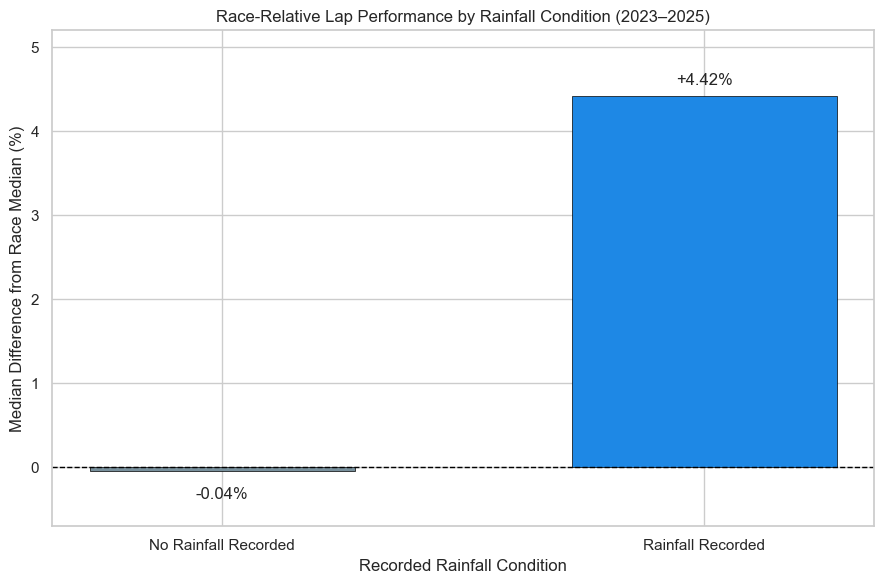

In [45]:
# Calculate the median percentage difference from the race median
rainfall_values = (
    rainfall_pace_summary["difference_from_race_median_pct"]
)

# Define readable labels for the two rainfall categories
rainfall_labels = [
    "No Rainfall Recorded",
    "Rainfall Recorded"
]

# Create the bar chart
fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(
    rainfall_labels,
    rainfall_values.values,
    color=["#78909C", "#1E88E5"],
    edgecolor="black",
    linewidth=0.5,
    width=0.55
)

# Add a reference line for the race median
ax.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

# Add percentage labels above or below each bar
for bar, value in zip(bars, rainfall_values.values):
    ax.annotate(
        f"{value:+.2f}%",
        xy=(bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 6 if value >= 0 else -12),
        textcoords="offset points",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )

# Add the graph title and axis labels
ax.set_title("Race-Relative Lap Performance by Rainfall Condition (2023–2025)")
ax.set_xlabel("Recorded Rainfall Condition")
ax.set_ylabel("Median Difference from Race Median (%)")

# Leave room for the percentage labels
ax.set_ylim(-0.7, 5.2)

# Display the graph
plt.tight_layout()
plt.show()

#### 3.10 Interpretation of Rainfall and Race-Relative Lap Performance

The analysis identified a descriptive difference in race-relative lap performance between observations with and without recorded rainfall.

Laps without recorded rainfall had a median pace ratio of approximately 0.9996, corresponding to a lap duration approximately 0.04% below the median for the associated race.

In comparison, laps associated with recorded rainfall had a median pace ratio of approximately 1.0442, corresponding to a lap duration approximately 4.42% above the associated race median.

The difference between the two groups was approximately 4.46 percentage points.

These findings indicate that laps associated with recorded rainfall generally had longer durations relative to their race medians than laps without recorded rainfall.

However, this relationship should not be interpreted as evidence that rainfall alone caused the observed difference. Wet track conditions may influence tyre selection, grip, visibility, and driving behaviour. Race interruptions and other conditions may also contribute to slower lap durations.

The comparison is further limited by the unequal number of observations: 72,034 laps without recorded rainfall compared with 2,455 laps associated with rainfall.

Additionally, the rainfall indicator does not measure precipitation intensity or directly establish whether the racing surface was wet. The analysis also does not account for differences between circuits, drivers, or individual race conditions.

Consequently, the results provide evidence of an association between recorded rainfall and race-relative lap performance, while further multivariable analysis is required to evaluate the predictive contribution of weather conditions alongside tyre characteristics.

### 4. Machine Learning Model Evaluation

#### 4.1 Model Evaluation Methodology

This section compares the predictive performance of three regression algorithms: Linear Regression, Gradient Boosting Regression, and Random Forest Regression.

The models were evaluated using five-fold cross-validation, with Formula 1 races used as grouping units. This approach ensured that laps from the same race were not simultaneously included in the training and validation portions of a fold.

The evaluated models used tyre compound, estimated tyre age, and circuit information as predictors of lap duration. Categorical variables were encoded using one-hot encoding.

Before fitting each model, training observations identified as overlapping recorded safety-car, virtual-safety-car, or red-flag periods were excluded. Observations from one race with insufficient race-control status information were also excluded from training.

These exclusions were applied only to the training portion of each fold. Validation observations were retained, including laps potentially affected by race interruptions. Consequently, the reported validation errors reflect prediction performance across the unfiltered validation laps rather than exclusively uninterrupted racing laps.

Model performance was assessed using Mean Absolute Error (MAE), expressed in seconds. Lower MAE values indicate smaller average absolute differences between predicted and recorded lap durations.

The cross-validation comparison was conducted using the 56 races allocated to the earlier training partition. Although a separate 14-race test partition was initially created, it had already been consulted during preliminary model development. It should therefore not be described as a completely untouched or independent final test set.

The following results compare

#### 4.2 Comparison of Machine Learning Models Across Cross-Validation Folds

The predictive performance of Linear Regression, Gradient Boosting Regression, and Random Forest Regression is compared using Mean Absolute Error (MAE).

The results are presented for each of the five race-grouped cross-validation folds. This allows the analysis to examine both overall predictive accuracy and variation in performance across different groups of races.

Lower MAE values indicate better predictive accuracy, as they represent smaller average absolute differences between predicted and actual lap durations.

The comparison uses the tyre-and-circuit feature configuration evaluated during the grouped cross-validation experiments.

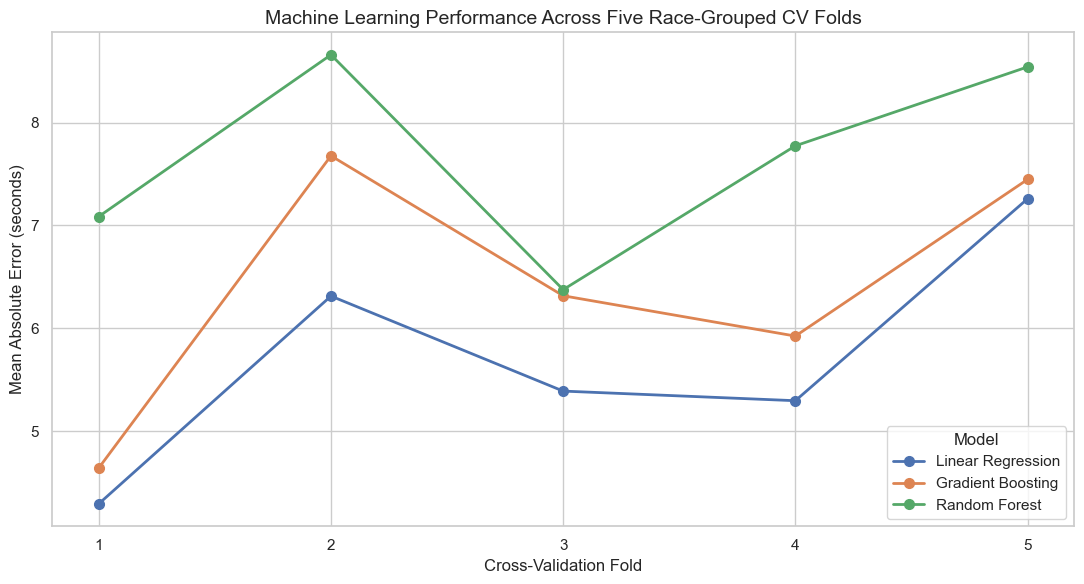

,Mean MAE (seconds),Standard Deviation (seconds)
Linear Regression,5.71,1.00
Gradient Boosting,6.40,1.10
Random Forest,7.69,0.87


In [46]:
# Select the three models from our saved results
model_names = [
    "Linear Regression",
    "Gradient Boosting",
    "Random Forest"
]

# Create the comparison graph
plt.figure(figsize=(11, 6))

# Draw one line for each machine learning model
for model in model_names:
    plt.plot(
        cv_results["Fold"],
        cv_results[model],
        marker="o",
        linewidth=2,
        markersize=7,
        label=model
    )

# Add a clear title and axis labels
plt.title(
    "Machine Learning Performance Across Five Race-Grouped CV Folds",
    fontsize=14
)
plt.xlabel("Cross-Validation Fold")
plt.ylabel("Mean Absolute Error (seconds)")

# Display each fold as a separate value
plt.xticks([1, 2, 3, 4, 5])

# Add the legend
plt.legend(title="Model")

# Improve spacing and display the graph
plt.tight_layout()
plt.show()

# Calculate the mean and standard deviation of MAE for each model
model_summary = pd.DataFrame({
    "Mean MAE (seconds)": cv_results[model_names].mean(),
    "Standard Deviation (seconds)": cv_results[model_names].std(ddof=0)
}).round(2)

# Display the summary table, ranked by mean MAE
display(model_summary.sort_values("Mean MAE (seconds)"))

#### 4.3 Interpretation of Cross-Validation Model Performance

The five-fold race-grouped cross-validation results indicate that Linear Regression achieved the lowest mean absolute error among the three evaluated algorithms.

Linear Regression recorded a mean MAE of 5.71 seconds, compared with 6.40 seconds for Gradient Boosting Regression and 7.69 seconds for Random Forest Regression.

Linear Regression also achieved the lowest MAE in all five validation folds, indicating consistently better predictive accuracy than the other two algorithms under the evaluated tyre-and-circuit feature configuration.

The difference in mean MAE between Linear Regression and Gradient Boosting was approximately 0.69 seconds, while the difference between Linear Regression and Random Forest was approximately 1.98 seconds.

The standard deviation of fold-level MAE was 1.00 seconds for Linear Regression, 1.10 seconds for Gradient Boosting, and 0.87 seconds for Random Forest.

Although Random Forest showed the lowest standard deviation, it also produced the highest mean prediction error. Lower variability between folds should therefore not be confused with superior predictive accuracy.

The results demonstrate that increasing model complexity did not improve predictive performance in this particular evaluation. A possible explanation is that the simpler Linear Regression model generalised more effectively to the held-out race groups, although the cross-validation results alone do not establish the underlying reason.

Importantly, the comparison was based on tyre compound, estimated tyre age, and circuit information. It does not yet establish whether weather variables improve predictive performance.

Furthermore, the validation folds included laps affected by race interruptions, while identified disrupted laps were excluded from model training. The reported MAE values therefore reflect performance across a broader range of race conditions than uninterrupted racing alone.

These findings support Linear Regression as the strongest-performing algorithm among the three models evaluated in this cross-validation experiment. However, the results should be interpreted as development-stage evaluation findings rather than an entirely independent final assessment, because earlier model-development decisions had already been informed by held-out race results.

#### 4.4 Weather-Inclusive Gradient Boosting Comparison

To investigate whether weather measurements improve lap-time prediction, a weather-inclusive Gradient Boosting model was evaluated using the same five race-grouped cross-validation folds as the tyre-and-circuit models.

The weather-inclusive configuration added air temperature, track temperature, humidity, rainfall, wind speed, and atmospheric pressure to the existing tyre compound, estimated tyre age, and circuit predictors.

The model settings and training-data exclusions were kept consistent with the earlier Gradient Boosting experiment, allowing the predictive performance of the two feature configurations to be compared.

The following analysis compares their fold-level Mean Absolute Error (MAE) values.

In [47]:
# Reload the updated cross-validation results from our experiment notebook
cv_results = pd.read_csv("f1_model_cv_results.csv")

# Check that all four model configurations are present
print(cv_results.columns.tolist())

# Display the five-fold comparison
display(cv_results.round(2))

['Fold', 'Linear Regression', 'Gradient Boosting', 'Random Forest', 'Gradient Boosting + Weather', 'Linear Regression + Weather']


,Fold,Linear Regression,Gradient Boosting,Random Forest,Gradient Boosting + Weather,Linear Regression + Weather
0,1,4.29,4.64,7.09,4.19,4.71
1,2,6.31,7.68,8.66,7.83,6.38
2,3,5.39,6.32,6.38,8.13,5.52
3,4,5.30,5.92,7.77,7.72,5.89
4,5,7.26,7.45,8.54,8.32,8.19


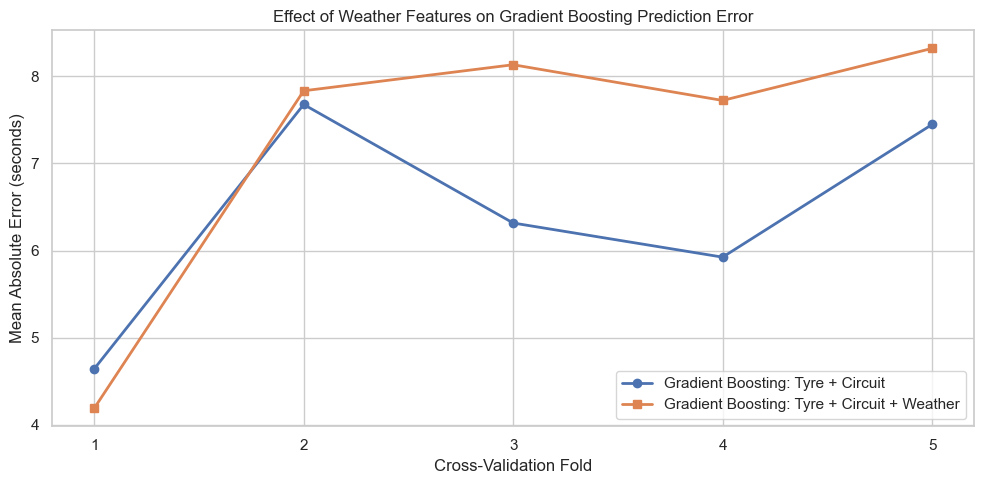

In [48]:
# Set up the chart showing both Gradient Boosting configurations
plt.figure(figsize=(10, 5))

# Plot Gradient Boosting using tyre and circuit information
plt.plot(
    cv_results["Fold"],
    cv_results["Gradient Boosting"],
    marker="o",
    linewidth=2,
    label="Gradient Boosting: Tyre + Circuit"
)

# Plot Gradient Boosting with weather information added
plt.plot(
    cv_results["Fold"],
    cv_results["Gradient Boosting + Weather"],
    marker="s",
    linewidth=2,
    label="Gradient Boosting: Tyre + Circuit + Weather"
)

# Add a clear title and axis labels
plt.title("Effect of Weather Features on Gradient Boosting Prediction Error")
plt.xlabel("Cross-Validation Fold")
plt.ylabel("Mean Absolute Error (seconds)")

# Show the five individual race-grouped folds
plt.xticks(cv_results["Fold"])

# Add a legend and improve the layout
plt.legend()
plt.tight_layout()

# Display the completed chart
plt.show()

#### 4.5 Interpretation of the Weather-Inclusive Model Comparison

The five-fold race-grouped cross-validation results indicate that adding weather variables did not consistently improve the predictive performance of Gradient Boosting Regression.

The tyre-and-circuit Gradient Boosting model achieved a mean MAE of approximately **6.40 seconds**, compared with **7.24 seconds** for the weather-inclusive configuration. The inclusion of weather measurements therefore increased the average prediction error by approximately **0.84 seconds**, representing an increase of roughly **13%**.

The weather-inclusive model performed better in Fold 1, reducing MAE from approximately 4.64 seconds to 4.19 seconds. However, it produced higher prediction errors in the remaining four folds. The largest differences occurred in Folds 3 and 4, where the weather-inclusive model's MAE was approximately 1.81 and 1.80 seconds higher, respectively.

These findings suggest that the additional weather predictors did not generalise consistently across the held-out race groups under the evaluated model configuration.

Importantly, this result does **not** demonstrate that weather conditions have no influence on Formula 1 lap performance. The exploratory analysis identified associations between weather measurements and relative lap duration. However, relationships observed within the dataset do not necessarily translate into improved predictive accuracy when a model is evaluated on different races.

Potential explanations include differences in weather conditions between races, relationships between weather measurements and circuit characteristics, and the difficulty of distinguishing weather effects from other factors influencing lap times. These explanations remain hypotheses rather than established causes of the observed prediction errors.

The comparison was conducted using the same race-grouped cross-validation folds, Gradient Boosting settings, and training-data exclusions. This supports a controlled comparison of the two feature configurations.

Nevertheless, the findings apply specifically to the evaluated Gradient Boosting models. They do not establish whether adding weather variables would improve Linear Regression or Random Forest performance. Furthermore, the cross-validation results represent development-stage evaluation rather than a fully independent final assessment.

Overall, the results indicate that adding the available weather measurements increased the average prediction error of Gradient Boosting Regression in this experiment, despite improving performance in one validation fold.

#### 4.6 Weather-Inclusive Linear Regression Comparison

Following the Gradient Boosting weather-feature experiment, Linear Regression was also evaluated with the addition of weather measurements.

The weather-inclusive Linear Regression model used the same five race-grouped cross-validation folds, training-data exclusions, and regression algorithm as the original tyre-and-circuit configuration.

Six weather predictors were added: air temperature, track temperature, humidity, rainfall, wind speed, and atmospheric pressure.

This comparison investigates whether weather measurements improve the predictive performance of Linear Regression, which achieved the lowest average MAE among the original three algorithms.

The following analysis compares prediction errors across the five validation folds.

In [49]:
# Reload the updated CSV containing all five model configurations
cv_results = pd.read_csv("f1_model_cv_results.csv")

# Confirm that the weather-inclusive Linear Regression results are present
print(cv_results.columns.tolist())

# Display the fold-level Linear Regression comparison
display(
    cv_results[
        ["Fold", "Linear Regression", "Linear Regression + Weather"]
    ].round(2)
)

['Fold', 'Linear Regression', 'Gradient Boosting', 'Random Forest', 'Gradient Boosting + Weather', 'Linear Regression + Weather']


,Fold,Linear Regression,Linear Regression + Weather
0,1,4.29,4.71
1,2,6.31,6.38
2,3,5.39,5.52
3,4,5.30,5.89
4,5,7.26,8.19


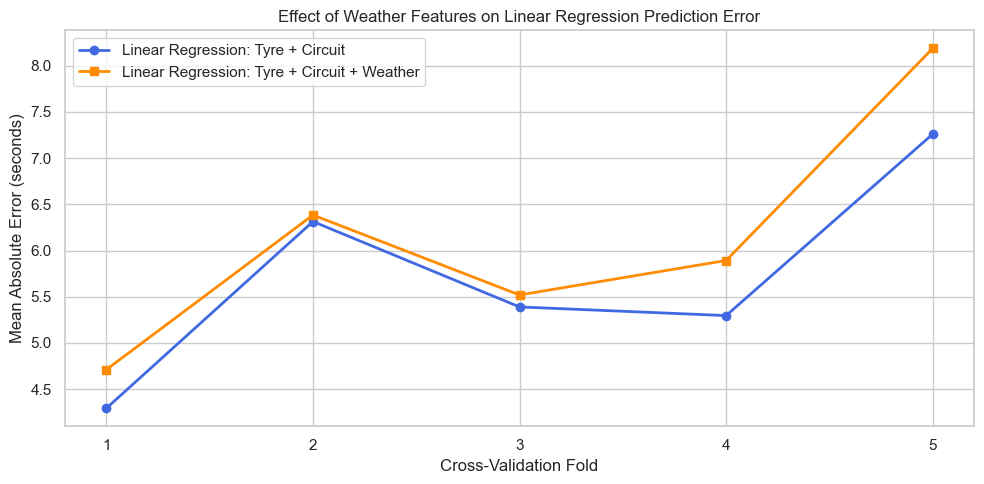

In [50]:
# Create a chart comparing Linear Regression with and without weather
plt.figure(figsize=(10, 5))

# Plot Linear Regression using tyre and circuit predictors
plt.plot(
    cv_results["Fold"],
    cv_results["Linear Regression"],
    marker="o",
    linewidth=2,
    color="royalblue",
    label="Linear Regression: Tyre + Circuit"
)

# Plot Linear Regression with weather predictors added
plt.plot(
    cv_results["Fold"],
    cv_results["Linear Regression + Weather"],
    marker="s",
    linewidth=2,
    color="darkorange",
    label="Linear Regression: Tyre + Circuit + Weather"
)

# Add the chart title and axis labels
plt.title("Effect of Weather Features on Linear Regression Prediction Error")
plt.xlabel("Cross-Validation Fold")
plt.ylabel("Mean Absolute Error (seconds)")

# Show all five race-grouped validation folds
plt.xticks(cv_results["Fold"])

# Add the legend and improve spacing
plt.legend()
plt.tight_layout()

# Display the chart
plt.show()

#### 4.7 Interpretation of the Weather-Inclusive Linear Regression Results

The five-fold race-grouped cross-validation results indicate that adding weather measurements did not improve the predictive accuracy of Linear Regression under the evaluated experimental conditions.

The tyre-and-circuit Linear Regression model achieved a mean MAE of approximately **5.71 seconds**, compared with **6.14 seconds** for the weather-inclusive configuration. Adding weather predictors therefore increased the average prediction error by approximately **0.43 seconds**, representing an increase of roughly **7.5%**.

The tyre-and-circuit model achieved lower prediction errors in all five validation folds. The smallest difference occurred in Fold 2, where MAE increased from approximately 6.31 seconds to 6.38 seconds after adding weather variables.

The largest difference occurred in Fold 5, where the weather-inclusive model recorded an MAE of approximately 8.19 seconds, compared with 7.26 seconds for the tyre-and-circuit model.

This pattern suggests that the additional weather measurements did not improve the model's ability to generalise to the held-out race groups.

The comparison was conducted using identical race-grouped cross-validation folds, the same Linear Regression algorithm, and consistent training-data exclusions. This supports a controlled comparison between the two feature configurations.

These findings are consistent with the Gradient Boosting experiment, in which adding weather measurements also increased average prediction error. However, the effect was smaller for Linear Regression, and the weather-inclusive Gradient Boosting model did improve performance in one validation fold.

Importantly, these results do not demonstrate that weather conditions have no influence on Formula 1 performance. They indicate that the available weather measurements did not provide a predictive advantage for the two evaluated algorithms under the tested configurations.

Possible explanations include differences in conditions between races, correlations among weather predictors, and relationships between weather measurements and circuit characteristics. Further analysis would be required to determine which factors contributed to the observed results.

The results should also be interpreted as development-stage cross-validation findings rather than a fully independent final assessment.

Overall, **Linear Regression using tyre compound, estimated tyre age, and circuit information remained the strongest-performing configuration among the five models evaluated**, achieving the lowest average cross-validation MAE of approximately 5.71 seconds.

#### 4.8 Overall Model Performance Comparison

The following table summarises the predictive performance of all five evaluated model configurations across the five race-grouped cross-validation folds.

Mean Absolute Error (MAE) is reported in seconds. Lower values indicate more accurate lap-duration predictions.

The standard deviation describes how much the MAE varied between validation folds.

In [51]:
# Select the five model configurations, excluding the Fold column
model_columns = [
    "Linear Regression",
    "Linear Regression + Weather",
    "Gradient Boosting",
    "Gradient Boosting + Weather",
    "Random Forest"
]

# Calculate average prediction error and variability across the five folds
overall_model_summary = pd.DataFrame({
    "Mean MAE (seconds)": cv_results[model_columns].mean(),
    "MAE Standard Deviation (seconds)": cv_results[model_columns].std(ddof=0)
})

# Sort the models from lowest to highest average prediction error
overall_model_summary = overall_model_summary.sort_values(
    "Mean MAE (seconds)"
)

# Display the final comparison table
display(overall_model_summary.round(2))

,Mean MAE (seconds),MAE Standard Deviation (seconds)
Linear Regression,5.71,1.00
Linear Regression + Weather,6.14,1.16
Gradient Boosting,6.40,1.10
Gradient Boosting + Weather,7.24,1.54
Random Forest,7.69,0.87


#### 4.9 Interpretation of Overall Model Performance

The five-fold race-grouped cross-validation results provide a comparative assessment of five machine-learning model configurations for predicting Formula 1 lap duration.

**Linear Regression using tyre compound, estimated tyre age, and circuit information achieved the lowest mean MAE of 5.71 seconds.** This configuration outperformed all other evaluated models in terms of average prediction error.

Adding weather measurements to Linear Regression increased its mean MAE to 6.14 seconds. Similarly, adding weather measurements to Gradient Boosting increased its mean MAE from 6.40 seconds to 7.24 seconds.

These results indicate that the inclusion of the available weather variables did not improve average predictive accuracy for either of the two algorithms evaluated with and without weather information.

Random Forest recorded the highest mean MAE of 7.69 seconds, despite having the lowest standard deviation of fold-level errors at 0.87 seconds. This demonstrates that relatively consistent performance across folds does not necessarily indicate superior predictive accuracy.

The weather-inclusive Gradient Boosting model exhibited the highest fold-level MAE standard deviation of 1.54 seconds, suggesting greater variability in its predictive performance across the evaluated race groups.

The findings also show that more complex algorithms did not necessarily outperform the simpler Linear Regression model. However, the results do not establish why the algorithms differed in performance.

The comparison was conducted using race-grouped cross-validation to prevent laps from the same race appearing in both the training and validation portions of an individual fold. Identified race-control disruptions and laps with unknown race-control status were excluded from training, while validation laps remained unfiltered.

Consequently, the reported MAE values describe predictive performance across the evaluated validation laps, including laps potentially affected by race interruptions.

Although weather measurements did not improve the evaluated models' average predictive accuracy, this finding should not be interpreted as evidence that weather has no effect on Formula 1 performance. The predictive contribution of weather variables is distinct from their physical or statistical relationship with lap duration.

Furthermore, these results are development-stage cross-validation findings rather than a fully independent final assessment, because earlier model-development decisions had been informed by held-out race results.

Overall, the results support **tyre-and-circuit Linear Regression as the leading model configuration for subsequent diagnostic analysis**, while highlighting the limitations of the evaluated weather-inclusive configurations.

### 5. Linear Regression Model Diagnostics

Following the five-fold race-grouped cross-validation comparison, additional diagnostic analyses were conducted on the Linear Regression model, which achieved the lowest mean cross-validation error among the five evaluated model configurations.

The diagnostic dataset contains **58,814 out-of-fold predictions**, with each prediction generated for a validation lap by a model trained without that lap's race session. Race-control-based exclusions were applied only to the training portion of each fold; validation laps were retained for evaluation.

The following analyses examine prediction errors across opening and subsequent race laps, tyre compounds, individual circuits, and circuits that were either represented or absent from the corresponding fold's training data.

These analyses aim to identify patterns in model performance and limitations in generalisation. They do not alter the original cross-validation scores or establish causal relationships between the examined characteristics and prediction errors.

In [52]:
# Load the saved out-of-fold Linear Regression predictions
# These predictions cover all five race-grouped validation folds
cv_diagnostics = pd.read_csv(
    "f1_linear_cv_diagnostics.csv"
)

# Confirm the diagnostic dataset loaded correctly
print("Diagnostic rows:", len(cv_diagnostics))
print("Diagnostic columns:", len(cv_diagnostics.columns))

# Show the available columns
print("\nColumns:")
print(cv_diagnostics.columns.tolist())

Diagnostic rows: 58814
Diagnostic columns: 11

Columns:
['fold', 'actual_lap_duration', 'predicted_lap_duration', 'lap_number', 'error_seconds', 'absolute_error', 'lap_category', 'compound', 'circuit', 'session_key', 'circuit_status']


In [53]:
# Compare prediction errors between opening laps and later laps
lap_category_summary = (
    cv_diagnostics
    .groupby("lap_category")
    .agg(
        lap_count=("absolute_error", "size"),
        mae_seconds=("absolute_error", "mean"),
        mean_signed_error=("error_seconds", "mean")
    )
)

# Calculate the percentage of validation laps in each category
lap_category_summary["lap_percentage"] = (
    lap_category_summary["lap_count"]
    / len(cv_diagnostics)
    * 100
)

# Display the results rounded to two decimal places
display(lap_category_summary.round(2))

,lap_count,mae_seconds,mean_signed_error,lap_percentage
lap_category,,,,
Later lap,57815,5.55,-1.35,98.3
Opening lap,999,16.04,-15.71,1.7


#### 5.1 Prediction Errors on Opening and Subsequent Laps

The Linear Regression model exhibited substantially different prediction accuracy between opening laps and subsequent race laps.

Across **999 opening laps**, representing **1.70%** of the validation observations, the model achieved a mean absolute error (MAE) of **16.04 seconds**. In comparison, the MAE across **57,815 subsequent laps** was **5.55 seconds**. Opening-lap prediction errors were therefore approximately **2.89 times higher**.

The mean signed prediction error was **−15.71 seconds** for opening laps, compared with **−1.35 seconds** for subsequent laps. As signed error was calculated as predicted minus actual lap duration, these negative values indicate a tendency to underestimate lap times, particularly during opening laps.

A plausible explanation is that opening laps include standing starts, initial acceleration and race-start traffic conditions that are not explicitly represented by the model's tyre-compound, estimated tyre-age and circuit predictors. However, the diagnostic comparison does not establish which factors caused the observed errors.

These findings indicate that the model is less accurate when predicting opening-lap performance. They also demonstrate the importance of examining prediction errors across different racing situations rather than relying exclusively on an overall cross-validation MAE.

In [54]:
# Calculate prediction errors separately for each tyre compound
compound_diagnostics = (
    cv_diagnostics
    .groupby("compound")
    .agg(
        lap_count=("absolute_error", "size"),
        mae_seconds=("absolute_error", "mean"),
        mean_signed_error=("error_seconds", "mean")
    )
)

# Sort compounds from lowest to highest prediction error
compound_diagnostics = compound_diagnostics.sort_values(
    "mae_seconds"
)

# Display the tyre-compound comparison
display(compound_diagnostics.round(2))

,lap_count,mae_seconds,mean_signed_error
compound,,,
SOFT,6188,4.83,-2.17
HARD,27186,5.30,-1.34
MEDIUM,22118,5.97,-1.13
INTERMEDIATE,3294,9.10,-5.71
WET,28,22.30,-12.45


#### 5.2 Prediction Errors by Tyre Compound

Prediction accuracy varied across the five tyre compounds represented in the validation data.

The Linear Regression model achieved its lowest mean absolute error (MAE) on **SOFT tyres (4.83 seconds)**, followed by **HARD tyres (5.30 seconds)** and **MEDIUM tyres (5.97 seconds)**. Prediction errors were higher for **INTERMEDIATE tyres (9.10 seconds)** and **WET tyres (22.30 seconds)**.

The three dry-weather compounds accounted for most validation observations, whereas INTERMEDIATE tyres were represented by 3,294 laps and WET tyres by only 28 laps. Consequently, the WET-tyre result is based on a particularly limited sample and should not be treated as a reliable estimate of performance across wet-weather races.

Additional investigation of the WET-tyre predictions identified 15 laps from the 2024 Canadian Grand Prix and 13 laps from the 2024 São Paulo Grand Prix. Twelve of the 13 São Paulo WET-tyre laps overlapped recorded safety-car, virtual-safety-car or red-flag intervals. These disruptions contributed to unusually large prediction errors in that race, although the available evidence does not establish that they explain all WET-tyre errors.

The mean signed errors were negative for all five compounds, indicating an overall tendency to underestimate lap durations within each compound category. The strongest negative mean signed errors occurred for INTERMEDIATE and WET tyres.

These findings suggest that the model's predictive accuracy differs across tyre compounds and racing conditions. However, differences in sample size, circuit characteristics, weather conditions and race-control disruptions limit direct comparisons. The results describe prediction performance rather than the causal effects of tyre compounds on Formula 1 lap times.

In [55]:
# Calculate prediction errors for each circuit
circuit_diagnostics = (
    cv_diagnostics
    .groupby("circuit")
    .agg(
        lap_count=("absolute_error", "size"),
        race_count=("session_key", "nunique"),
        mae_seconds=("absolute_error", "mean"),
        mean_signed_error=("error_seconds", "mean")
    )
)

# Sort circuits from highest to lowest prediction error
circuit_diagnostics = circuit_diagnostics.sort_values(
    "mae_seconds",
    ascending=False
)

# Display the circuit-level diagnostic results
display(circuit_diagnostics.round(2))

,lap_count,race_count,mae_seconds,mean_signed_error
circuit,,,,
Spielberg,2380,2,18.96,17.82
Las Vegas,912,1,17.74,-17.74
Imola,1168,1,10.57,3.72
Suzuka,2724,3,9.65,-9.65
Sakhir,1005,1,9.16,-9.16
Shanghai,1040,1,9.11,-9.11
Silverstone,1701,2,7.82,-5.21
Budapest,1339,1,7.46,7.38
Melbourne,2690,3,7.42,-5.97


#### 5.3 Prediction Errors Across Circuits

Prediction accuracy varied substantially across the 24 circuits represented in the cross-validation diagnostics.

The highest mean absolute errors (MAEs) were observed at **Spielberg (18.96 seconds)**, **Las Vegas (17.74 seconds)** and **Imola (10.57 seconds)**. In contrast, the lowest errors occurred at **Yas Island (1.48 seconds)**, **Barcelona (2.04 seconds)** and **Monza (2.79 seconds)**.

The number of races represented at each circuit varied. For example, the Las Vegas and Imola results were each based on a single race, whereas Spielberg was represented by two races and Suzuka by three. Consequently, circuit-level error estimates based on fewer races should be interpreted cautiously.

Further examination of Spielberg showed similar errors in both represented races. Session 9118 had an MAE of **18.92 seconds**, while session 9955 had an MAE of **19.01 seconds**. The model overpredicted average lap duration by approximately 18 seconds in both races.

An investigation of the cross-validation splits established that both Spielberg races were assigned to the same validation fold, with **no Spielberg races available in that fold's training data**. Because circuit identity was encoded using one-hot encoding with unknown categories ignored, the model could not apply a previously learned Spielberg-specific adjustment.

This provides a plausible explanation for the unusually large prediction errors at Spielberg, although it does not establish that the absence of circuit-specific training observations was their sole cause.

Overall, these findings indicate that prediction accuracy depends partly on the racing contexts represented in the training data. They also highlight the importance of distinguishing performance at previously encountered circuits from generalisation to unfamiliar circuits.

In [56]:
# Compare prediction accuracy at familiar and unfamiliar circuits
circuit_status_summary = (
    cv_diagnostics
    .groupby("circuit_status")
    .agg(
        lap_count=("absolute_error", "size"),
        mae_seconds=("absolute_error", "mean"),
        mean_signed_error=("error_seconds", "mean")
    )
)

# Calculate the percentage of validation laps in each group
circuit_status_summary["lap_percentage"] = (
    circuit_status_summary["lap_count"]
    / len(cv_diagnostics)
    * 100
)

# Display the comparison rounded to two decimal places
display(circuit_status_summary.round(2))

,lap_count,mae_seconds,mean_signed_error,lap_percentage
circuit_status,,,,
Seen circuit,47723,4.32,-1.83,81.14
Unseen circuit,11091,11.78,-0.59,18.86


#### 5.4 Generalisation to Seen and Unseen Circuits

The cross-validation predictions were examined to determine whether model accuracy differed between circuits represented in the corresponding training fold and circuits absent from that fold's training data.

The Linear Regression model achieved a mean absolute error (MAE) of **4.32 seconds across 47,723 validation laps at seen circuits**, representing **81.14%** of the evaluated laps. At unseen circuits, the MAE increased to **11.78 seconds across 11,091 laps**, representing **18.86%** of the validation observations.

The MAE at unseen circuits was approximately **2.73 times higher** than at seen circuits, indicating substantially weaker predictive performance in this subset of the validation data.

The model incorporated circuit identity through one-hot encoding, with unknown categories ignored during transformation. Consequently, circuits absent from a training fold could not receive a circuit-specific adjustment learned from previous observations at that location. This is a plausible contributor to the higher errors observed at unfamiliar circuits.

However, the comparison does not establish a causal effect of circuit familiarity. The seen and unseen groups contain different races, circuits and racing conditions, which may also influence prediction accuracy.

These results demonstrate that the five-fold race-grouped cross-validation evaluates performance across two distinct situations: new races at previously encountered circuits and races at circuits entirely absent from training. The distinction is important when interpreting the overall cross-validation MAE and assessing the model's potential generalisation to future Formula 1 events.

The original cross-validation scores remain unchanged. This diagnostic analysis provides additional context for the model's predictive limitations rather than a revised estimate of overall performance.

In [57]:
# Count the total number of unique Formula 1 race sessions
total_races = f1_data["session_key"].nunique()

# Extract the year from each lap's recorded start date
race_years = pd.to_datetime(
    f1_data["date_start"],
    utc=True,
    format="mixed"
).dt.year

# Count distinct races represented in each year
races_per_year = (
    f1_data
    .assign(year=race_years)
    .groupby("year")["session_key"]
    .nunique()
)

# Display the dataset coverage
print("Total unique races:", total_races)
print("\nRaces per year:")
print(races_per_year)

Total unique races: 70

Races per year:
year
2023.0    22
2024.0    24
2025.0    24
Name: session_key, dtype: int64


#### 6. Dataset Coverage and Reproducibility Checks

The final model-ready dataset contains observations from **70 Formula 1 race sessions** across the 2023–2025 seasons. These comprise **22 races from 2023**, **24 races from 2024**, and **24 races from 2025**.

The race counts were verified using unique session identifiers in the final dataset, rather than relying solely on the number of races requested during data collection.

The final analysis notebook was also restarted and executed successfully from beginning to end, confirming that its analysis cells run in sequence using the saved input datasets.

These checks support the consistency and reproducibility of the reported descriptive analyses and model diagnostics. However, the final analysis notebook uses previously generated cross-validation results and predictions; reproducing the complete modelling process also requires the earlier data-preparation and machine-learning notebooks.

#### 6.1 Model Evaluation and Methodological Limitations

The dataset was initially divided by race session into a training portion containing **56 races** and a held-out portion containing **14 races**, using a group-based split to prevent observations from the same race appearing in both portions.

During exploratory model development, results from the original held-out portion were examined while comparing model configurations. Consequently, this portion cannot subsequently be treated as a completely untouched, independent final test set.

The principal model comparison presented in this analysis therefore uses **five-fold GroupKFold cross-validation within the original 56-race training portion**. Each validation fold contains race sessions excluded from that fold's model-fitting data, preventing direct overlap of race sessions between training and validation.

Recorded safety-car, virtual-safety-car and red-flag disruptions were used to exclude affected observations from fold training data, alongside observations from a session with insufficient race-control status information. Validation observations were retained without these exclusions. Therefore, the reported validation errors describe performance across the retained evaluation laps, including potentially disrupted racing conditions, rather than exclusively uninterrupted green-flag laps.

The cross-validation results provide evidence about predictive performance across the evaluated race groups and model configurations. However, because model development involved earlier exploratory comparisons, these results should be interpreted as **development-stage estimates**, not as an entirely independent or unbiased final assessment of generalisation performance.

This distinction is retained when interpreting the reported model rankings and their applicability to future Formula 1 races.

In [59]:
# Select the variables relevant to our research hypothesis
hypothesis_columns = [
    "lap_duration",
    "compound",
    "tyre_age",
    "air_temperature",
    "track_temperature",
    "humidity",
    "rainfall",
    "wind_speed",
    "pressure",
    "session_key"
]

# Keep observations with complete information for these variables
hypothesis_data = f1_data[hypothesis_columns].dropna().copy()

# Check the number of usable laps and distinct races
print("Complete observations:", len(hypothesis_data))
print("Unique races:", hypothesis_data["session_key"].nunique())

# Check how many observations belong to each tyre compound
print("\nTyre compound counts:")
print(hypothesis_data["compound"].value_counts())

Complete observations: 74489
Unique races: 70

Tyre compound counts:
compound
HARD            35223
MEDIUM          27143
SOFT             8100
INTERMEDIATE     3951
WET                72
Name: count, dtype: int64


In [61]:
# Import statsmodels for statistical regression and hypothesis testing
import statsmodels.formula.api as smf

In [62]:
# Create a separate dataset for statistical regression
# This keeps our original hypothesis_data unchanged
regression_data = hypothesis_data.copy()

# Treat race sessions as categorical identifiers
# This will allow us to account for race-specific differences
regression_data["session_key"] = (
    regression_data["session_key"].astype("category")
)

# Treat tyre compound as a categorical predictor
regression_data["compound"] = (
    regression_data["compound"].astype("category")
)

# Confirm the variables are ready
print("Regression observations:", len(regression_data))
print("Race sessions:", regression_data["session_key"].nunique())

print("\nVariable types:")
print(regression_data.dtypes)

Regression observations: 74489
Race sessions: 70

Variable types:
lap_duration          float64
compound             category
tyre_age              float64
air_temperature       float64
track_temperature     float64
humidity              float64
rainfall              float64
wind_speed            float64
pressure              float64
session_key          category
dtype: object


In [63]:
# Define the regression model using tyre and weather predictors
# C(compound) treats tyre compound as a categorical variable
# C(session_key) controls for differences between individual races
regression_formula = (
    "lap_duration ~ C(compound) + tyre_age "
    "+ air_temperature + track_temperature "
    "+ humidity + rainfall + wind_speed + pressure "
    "+ C(session_key)"
)

# Fit ordinary least squares regression
# Clustered standard errors account for observations within the same race
hypothesis_model = smf.ols(
    formula=regression_formula,
    data=regression_data
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": regression_data["session_key"]
    }
)

# Display the regression coefficient results
display(hypothesis_model.summary().tables[1])

/Users/tashmikamaharaj/anaconda3/lib/python3.10/site-packages/statsmodels/base/model.py:1871: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 80, but rank is 11
  warnings.warn('covariance of constraints does not have full '


,coef,std err,z,P>|z|,[0.025,0.975]
Intercept,1685.6144,1649.103,1.022,0.307,-1546.568,4917.797
C(compound)[T.INTERMEDIATE],7.2852,3.119,2.335,0.020,1.171,13.399
C(compound)[T.MEDIUM],0.1258,0.335,0.376,0.707,-0.531,0.782
C(compound)[T.SOFT],0.8495,0.552,1.538,0.124,-0.233,1.932
C(compound)[T.WET],19.1433,6.564,2.917,0.004,6.279,32.008
C(session_key)[T.7787],-13.4484,13.438,-1.001,0.317,-39.787,12.890
C(session_key)[T.7953],13.4301,11.163,1.203,0.229,-8.448,35.309
C(session_key)[T.9070],2.8469,5.608,0.508,0.612,-8.144,13.838
C(session_key)[T.9078],6.2147,11.381,0.546,0.585,-16.092,28.521
C(session_key)[T.9094],-16.1617,4.258,-3.796,0.000,-24.506,-7.817


In [64]:
# Test whether tyre compounds are statistically significant as a group
# HARD is the reference tyre, so it is not listed separately
tyre_compound_test = hypothesis_model.wald_test(
    "C(compound)[T.INTERMEDIATE] = 0, "
    "C(compound)[T.MEDIUM] = 0, "
    "C(compound)[T.SOFT] = 0, "
    "C(compound)[T.WET] = 0",
    scalar=True
)

# Display the statistical test results
print("Joint tyre compound test")
print("Test statistic:", tyre_compound_test.statistic)
print("P-value:", tyre_compound_test.pvalue)

Joint tyre compound test
Test statistic: 12.04082701037142
P-value: 0.017050233420231813


In [65]:
# Test whether all six weather coefficients are jointly zero
# This checks their combined statistical association with lap duration
weather_test = hypothesis_model.wald_test(
    "air_temperature = 0, "
    "track_temperature = 0, "
    "humidity = 0, "
    "rainfall = 0, "
    "wind_speed = 0, "
    "pressure = 0",
    scalar=True
)

# Display the joint weather test results
print("Joint weather conditions test")
print("Test statistic:", weather_test.statistic)
print("P-value:", weather_test.pvalue)

Joint weather conditions test
Test statistic: 11.104022940450026
P-value: 0.08521419311796387


In [66]:
# Test tyre compound and tyre age together
# This examines the joint association of tyre characteristics with lap duration
tyre_characteristics_test = hypothesis_model.wald_test(
    "C(compound)[T.INTERMEDIATE] = 0, "
    "C(compound)[T.MEDIUM] = 0, "
    "C(compound)[T.SOFT] = 0, "
    "C(compound)[T.WET] = 0, "
    "tyre_age = 0",
    scalar=True
)

# Display the joint test results
print("Joint tyre characteristics test")
print("Test statistic:", tyre_characteristics_test.statistic)
print("P-value:", tyre_characteristics_test.pvalue)

Joint tyre characteristics test
Test statistic: 60.2950601718718
P-value: 1.0562321735751561e-11


In [67]:
# Collect the names of all tyre and weather coefficients
# Race-session coefficients are excluded because they are control variables
research_predictors = [
    "C(compound)[T.INTERMEDIATE]",
    "C(compound)[T.MEDIUM]",
    "C(compound)[T.SOFT]",
    "C(compound)[T.WET]",
    "tyre_age",
    "air_temperature",
    "track_temperature",
    "humidity",
    "rainfall",
    "wind_speed",
    "pressure"
]

# Build a joint hypothesis that all research coefficients equal zero
overall_hypothesis = ", ".join(
    f"{predictor} = 0"
    for predictor in research_predictors
)

# Run the overall Wald test using race-clustered standard errors
overall_test = hypothesis_model.wald_test(
    overall_hypothesis,
    scalar=True
)

# Display the results
print("Overall research hypothesis test")
print("Test statistic:", overall_test.statistic)
print("P-value:", overall_test.pvalue)

Overall research hypothesis test
Test statistic: 93.70698308295404
P-value: 3.1195098780982675e-15


In [68]:
# Create a summary table of our four statistical hypothesis tests
hypothesis_results = pd.DataFrame({
    "Test": [
        "Tyre compounds",
        "Weather conditions",
        "Tyre characteristics",
        "Overall tyre and weather predictors"
    ],
    "Wald statistic": [
        tyre_compound_test.statistic,
        weather_test.statistic,
        tyre_characteristics_test.statistic,
        overall_test.statistic
    ],
    "P-value": [
        tyre_compound_test.pvalue,
        weather_test.pvalue,
        tyre_characteristics_test.pvalue,
        overall_test.pvalue
    ]
})

# Apply our chosen 5% significance threshold
hypothesis_results["Significant at 5%"] = (
    hypothesis_results["P-value"] < 0.05
)

# Save the results so they can be used in the dissertation
hypothesis_results.to_csv(
    "f1_hypothesis_test_results.csv",
    index=False
)

# Display the saved summary
display(hypothesis_results)

,Test,Wald statistic,P-value,Significant at 5%
0,Tyre compounds,12.040827,1.705023e-02,True
1,Weather conditions,11.104023,8.521419e-02,False
2,Tyre characteristics,60.295060,1.056232e-11,True
3,Overall tyre and weather predictors,93.706983,3.119510e-15,True


In [69]:
# Display the number of observations used in the regression
print("Observations:", int(hypothesis_model.nobs))

# R-squared measures the proportion of variation explained by the model
print("R-squared:", round(hypothesis_model.rsquared, 4))

# Adjusted R-squared accounts for the number of predictors
print("Adjusted R-squared:", round(hypothesis_model.rsquared_adj, 4))

# Calculate the average absolute difference between actual and fitted lap times
# This is an in-sample diagnostic, not a cross-validation result
regression_mae = abs(hypothesis_model.resid).mean()

print("In-sample MAE:", round(regression_mae, 4), "seconds")

Observations: 74489
R-squared: 0.6036
Adjusted R-squared: 0.6032
In-sample MAE: 4.5151 seconds


In [70]:
# Calculate the absolute regression error for every lap
absolute_residuals = hypothesis_model.resid.abs()

# Summarise the size of the regression errors
print("Median absolute error:", round(absolute_residuals.median(), 2), "seconds")
print("95th percentile error:", round(absolute_residuals.quantile(0.95), 2), "seconds")
print("99th percentile error:", round(absolute_residuals.quantile(0.99), 2), "seconds")
print("Largest absolute error:", round(absolute_residuals.max(), 2), "seconds")

# Count laps with particularly large errors
print("Laps with errors over 20 seconds:", int((absolute_residuals > 20).sum()))

Median absolute error: 2.51 seconds
95th percentile error: 14.01 seconds
99th percentile error: 45.26 seconds
Largest absolute error: 137.96 seconds
Laps with errors over 20 seconds: 2944


In [71]:
# Create a copy of the regression data for error analysis
residual_diagnostics = regression_data.copy()

# Add the absolute regression error for each lap
residual_diagnostics["absolute_error"] = hypothesis_model.resid.abs()

# Identify laps with an absolute error greater than 20 seconds
residual_diagnostics["large_error"] = (
    residual_diagnostics["absolute_error"] > 20
)

# Count large errors for each race
race_error_summary = (
    residual_diagnostics
    .groupby("session_key", observed=True)
    .agg(
        total_laps=("large_error", "size"),
        large_errors=("large_error", "sum")
    )
)

# Calculate the percentage of large errors within each race
race_error_summary["large_error_pct"] = (
    race_error_summary["large_errors"]
    / race_error_summary["total_laps"]
    * 100
)

# Display the ten races with the most large errors
display(
    race_error_summary
    .sort_values("large_errors", ascending=False)
    .head(10)
    .round(2)
)

,total_laps,large_errors,large_error_pct
session_key,,,
9693,838,189,22.55
9947,787,140,17.79
9920,1323,140,10.58
9149,1239,140,11.30
9673,989,137,13.85
9655,879,128,14.56
9987,1168,127,10.87
9869,1212,103,8.50
9531,1205,101,8.38


In [73]:
# Add lap numbers to our regression diagnostic dataset
# Match records using their original dataframe indices
# Retrieve lap numbers from our original analysis dataset
# The indices match the observations used in our regression
residual_diagnostics["lap_number"] = f1_data.loc[
    residual_diagnostics.index, "lap_number"
]

# Identify opening laps
residual_diagnostics["opening_lap"] = (
    residual_diagnostics["lap_number"] == 1
)

# Compare large regression errors for opening and later laps
opening_lap_errors = (
    residual_diagnostics
    .groupby("opening_lap")
    .agg(
        total_laps=("large_error", "size"),
        large_errors=("large_error", "sum"),
        median_absolute_error=("absolute_error", "median")
    )
)

# Calculate the percentage of laps with large errors
opening_lap_errors["large_error_pct"] = (
    opening_lap_errors["large_errors"]
    / opening_lap_errors["total_laps"]
    * 100
)

# Display the comparison
display(opening_lap_errors.round(2))

,total_laps,large_errors,median_absolute_error,large_error_pct
opening_lap,,,,
False,73216,2727,2.48,3.72
True,1273,217,6.18,17.05


In [74]:
# Count opening and later laps for each tyre compound
# This helps us understand the data before any sensitivity analysis
opening_compound_counts = pd.crosstab(
    residual_diagnostics["compound"],
    residual_diagnostics["opening_lap"]
)

# Give the columns clearer names
opening_compound_counts = opening_compound_counts.rename(
    columns={
        False: "Later laps",
        True: "Opening laps"
    }
)

# Display the comparison
display(opening_compound_counts)

opening_lap,Later laps,Opening laps
compound,,
HARD,35055,168
INTERMEDIATE,3884,67
MEDIUM,26365,778
SOFT,7840,260
WET,72,0


In [75]:
# Create a separate dataset that excludes opening laps
# Keep the original regression data unchanged
later_lap_data = regression_data.loc[
    residual_diagnostics["lap_number"] != 1
].copy()

# Fit the same regression using later laps only
# Keep race-specific controls and race-clustered standard errors
later_lap_model = smf.ols(
    formula=regression_formula,
    data=later_lap_data
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": later_lap_data["session_key"]
    }
)

# Display the number of observations and model fit
print("Later-lap observations:", int(later_lap_model.nobs))
print("R-squared:", round(later_lap_model.rsquared, 4))
print("In-sample MAE:", round(later_lap_model.resid.abs().mean(), 4))

Later-lap observations: 73216
R-squared: 0.6137
In-sample MAE: 4.206


In [76]:
# Repeat the overall hypothesis test using later laps only
# Use the same hypothesis we tested in the original regression
later_lap_overall_test = later_lap_model.wald_test(
    overall_hypothesis,
    scalar=True
)

# Compare the original and sensitivity-analysis results
print("Original model:")
print("P-value:", overall_test.pvalue)

print("\nModel excluding opening laps:")
print("Test statistic:", later_lap_overall_test.statistic)
print("P-value:", later_lap_overall_test.pvalue)

Original model:
P-value: 3.1195098780982675e-15

Model excluding opening laps:
Test statistic: 85.89515493814757
P-value: 1.0575263898124605e-13


In [77]:
# Test tyre characteristics in the model excluding opening laps
later_lap_tyre_test = later_lap_model.wald_test(
    "C(compound)[T.INTERMEDIATE] = 0, "
    "C(compound)[T.MEDIUM] = 0, "
    "C(compound)[T.SOFT] = 0, "
    "C(compound)[T.WET] = 0, "
    "tyre_age = 0",
    scalar=True
)

# Test weather conditions in the model excluding opening laps
later_lap_weather_test = later_lap_model.wald_test(
    "air_temperature = 0, "
    "track_temperature = 0, "
    "humidity = 0, "
    "rainfall = 0, "
    "wind_speed = 0, "
    "pressure = 0",
    scalar=True
)

# Compare the original and later-lap p-values
print("TYRE CHARACTERISTICS")
print("Original p-value:", tyre_characteristics_test.pvalue)
print("Later-lap p-value:", later_lap_tyre_test.pvalue)

print("\nWEATHER CONDITIONS")
print("Original p-value:", weather_test.pvalue)
print("Later-lap p-value:", later_lap_weather_test.pvalue)

TYRE CHARACTERISTICS
Original p-value: 1.0562321735751561e-11
Later-lap p-value: 5.99210900708486e-15

WEATHER CONDITIONS
Original p-value: 0.08521419311796387
Later-lap p-value: 0.01816874964235982


In [78]:
# Create a comparison of our original and sensitivity-analysis results
sensitivity_results = pd.DataFrame({
    "Hypothesis test": [
        "Tyre characteristics",
        "Weather conditions",
        "Overall research hypothesis"
    ],
    "All laps p-value": [
        tyre_characteristics_test.pvalue,
        weather_test.pvalue,
        overall_test.pvalue
    ],
    "Excluding opening laps p-value": [
        later_lap_tyre_test.pvalue,
        later_lap_weather_test.pvalue,
        later_lap_overall_test.pvalue
    ]
})

# Check significance using the 5% threshold
sensitivity_results["All laps significant"] = (
    sensitivity_results["All laps p-value"] < 0.05
)

sensitivity_results["Later laps significant"] = (
    sensitivity_results["Excluding opening laps p-value"] < 0.05
)

# Save the results for our dissertation
sensitivity_results.to_csv(
    "f1_hypothesis_sensitivity_results.csv",
    index=False
)

# Display the comparison
display(sensitivity_results)

,Hypothesis test,All laps p-value,Excluding opening laps p-value,All laps significant,Later laps significant
0,Tyre characteristics,1.056232e-11,5.992109e-15,True,True
1,Weather conditions,8.521419e-02,1.816875e-02,False,True
2,Overall research hypothesis,3.119510e-15,1.057526e-13,True,True


In [79]:
# Count how many races contain observations with rainfall
rainy_races = (
    regression_data
    .groupby("session_key", observed=True)["rainfall"]
    .agg(
        total_laps="size",
        rainy_laps=lambda values: (values > 0).sum()
    )
)

# Identify races containing at least one rainy observation
rainy_races["has_rain"] = rainy_races["rainy_laps"] > 0

# Display the overall rainfall coverage
print("Total races:", len(rainy_races))
print("Races with rainfall:", int(rainy_races["has_rain"].sum()))
print("Races without rainfall:", int((~rainy_races["has_rain"]).sum()))
print("Total rainy laps:", int(rainy_races["rainy_laps"].sum()))

Total races: 70
Races with rainfall: 10
Races without rainfall: 60
Total rainy laps: 2455


In [80]:
# Count races with rainfall in the later-lap dataset
later_rain_by_race = (
    later_lap_data
    .groupby("session_key", observed=True)["rainfall"]
    .apply(lambda values: (values > 0).any())
)

# Display rainfall coverage after excluding opening laps
print("Later-lap observations:", len(later_lap_data))
print("Races with rainfall:", int(later_rain_by_race.sum()))
print("Rainy later laps:", int((later_lap_data["rainfall"] > 0).sum()))

Later-lap observations: 73216
Races with rainfall: 10
Rainy later laps: 2455


In [81]:
# List the six weather variables used in our regression
weather_variables = [
    "air_temperature",
    "track_temperature",
    "humidity",
    "rainfall",
    "wind_speed",
    "pressure"
]

# Compare coefficients and p-values from both regression models
weather_comparison = pd.DataFrame({
    "All laps coefficient": hypothesis_model.params[weather_variables],
    "All laps p-value": hypothesis_model.pvalues[weather_variables],
    "Later laps coefficient": later_lap_model.params[weather_variables],
    "Later laps p-value": later_lap_model.pvalues[weather_variables]
})

# Round the results for easier reading
display(weather_comparison.round(4))

,All laps coefficient,All laps p-value,Later laps coefficient,Later laps p-value
air_temperature,-1.8151,0.0615,-1.5100,0.1028
track_temperature,0.4541,0.0294,0.3360,0.0925
humidity,0.0570,0.6821,0.1144,0.3783
rainfall,4.8063,0.0030,5.5282,0.0004
wind_speed,0.1724,0.6247,0.1969,0.5687
pressure,-1.5387,0.3449,-1.2178,0.4143


In [82]:
# Create a clean copy of our weather comparison
weather_sensitivity_results = weather_comparison.copy()

# Move the weather variable names into a normal column
weather_sensitivity_results = (
    weather_sensitivity_results
    .reset_index()
    .rename(columns={"index": "Weather variable"})
)

# Save the comparison for our dissertation results chapter
weather_sensitivity_results.to_csv(
    "f1_weather_sensitivity_results.csv",
    index=False
)

# Confirm that the file was saved
print("Weather sensitivity results saved successfully.")
print("Rows saved:", len(weather_sensitivity_results))

Weather sensitivity results saved successfully.
Rows saved: 6


In [83]:
# Check the distribution of lap durations
# This helps identify unusually long laps before further analysis

print("Median lap duration:",
      round(regression_data["lap_duration"].median(), 2),
      "seconds")

print("95th percentile:",
      round(regression_data["lap_duration"].quantile(0.95), 2),
      "seconds")

print("99th percentile:",
      round(regression_data["lap_duration"].quantile(0.99), 2),
      "seconds")

print("Longest lap:",
      round(regression_data["lap_duration"].max(), 2),
      "seconds")

# Count laps longer than two minutes
print("Laps over 120 seconds:",
      int((regression_data["lap_duration"] > 120).sum()))

Median lap duration: 89.17 seconds
95th percentile: 112.37 seconds
99th percentile: 145.37 seconds
Longest lap: 230.22 seconds
Laps over 120 seconds: 2520


In [84]:
# Calculate the median lap duration within each race
race_median_duration = regression_data.groupby(
    "session_key",
    observed=True
)["lap_duration"].transform("median")

# Compare each lap's duration with its race median
lap_duration_ratio = (
    regression_data["lap_duration"] / race_median_duration
)

# Count laps that are at least 50% slower than their race median
very_slow_laps = lap_duration_ratio > 1.5

# Display the results
print("Laps over 1.5 times their race median:",
      int(very_slow_laps.sum()))

print("Percentage of observations:",
      round(very_slow_laps.mean() * 100, 2), "%")

print("Races containing these laps:",
      regression_data.loc[
          very_slow_laps, "session_key"
      ].nunique())

Laps over 1.5 times their race median: 1349
Percentage of observations: 1.81 %
Races containing these laps: 42


In [85]:
# Create a separate dataset excluding unusually slow laps
# Keep the original regression data unchanged
normal_pace_data = regression_data.loc[
    ~very_slow_laps
].copy()

# Fit the same regression with race-specific controls
# Use race-clustered standard errors again
normal_pace_model = smf.ols(
    formula=regression_formula,
    data=normal_pace_data
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": normal_pace_data["session_key"]
    }
)

# Repeat our overall research hypothesis test
normal_pace_overall_test = normal_pace_model.wald_test(
    overall_hypothesis,
    scalar=True
)

# Compare the original and sensitivity-analysis results
print("Original observations:", int(hypothesis_model.nobs))
print("Sensitivity observations:", int(normal_pace_model.nobs))

print("\nOriginal overall p-value:", overall_test.pvalue)
print("Sensitivity overall p-value:", normal_pace_overall_test.pvalue)

Original observations: 74489
Sensitivity observations: 73140

Original overall p-value: 3.1195098780982675e-15
Sensitivity overall p-value: 5.733038417570033e-25


In [86]:
# Test tyre characteristics after excluding unusually slow laps
normal_pace_tyre_test = normal_pace_model.wald_test(
    "C(compound)[T.INTERMEDIATE] = 0, "
    "C(compound)[T.MEDIUM] = 0, "
    "C(compound)[T.SOFT] = 0, "
    "C(compound)[T.WET] = 0, "
    "tyre_age = 0",
    scalar=True
)

# Test weather conditions after excluding unusually slow laps
normal_pace_weather_test = normal_pace_model.wald_test(
    "air_temperature = 0, "
    "track_temperature = 0, "
    "humidity = 0, "
    "rainfall = 0, "
    "wind_speed = 0, "
    "pressure = 0",
    scalar=True
)

# Display the results for both groups of predictors
print("TYRE CHARACTERISTICS")
print("P-value:", normal_pace_tyre_test.pvalue)

print("\nWEATHER CONDITIONS")
print("P-value:", normal_pace_weather_test.pvalue)

TYRE CHARACTERISTICS
P-value: 1.0329065148350043e-19

WEATHER CONDITIONS
P-value: 0.00023417643418199743


In [87]:
# Create a summary of the three regression analyses
final_sensitivity_summary = pd.DataFrame({
    "Model": [
        "All laps",
        "Excluding opening laps",
        "Excluding unusually slow laps"
    ],
    "Observations": [
        int(hypothesis_model.nobs),
        int(later_lap_model.nobs),
        int(normal_pace_model.nobs)
    ],
    "Tyre p-value": [
        tyre_characteristics_test.pvalue,
        later_lap_tyre_test.pvalue,
        normal_pace_tyre_test.pvalue
    ],
    "Weather p-value": [
        weather_test.pvalue,
        later_lap_weather_test.pvalue,
        normal_pace_weather_test.pvalue
    ],
    "Overall p-value": [
        overall_test.pvalue,
        later_lap_overall_test.pvalue,
        normal_pace_overall_test.pvalue
    ]
})

# Save the complete comparison for the dissertation
final_sensitivity_summary.to_csv(
    "f1_final_sensitivity_summary.csv",
    index=False
)

# Display the results
display(final_sensitivity_summary)

,Model,Observations,Tyre p-value,Weather p-value,Overall p-value
0,All laps,74489,1.056232e-11,0.085214,3.119510e-15
1,Excluding opening laps,73216,5.992109e-15,0.018169,1.057526e-13
2,Excluding unusually slow laps,73140,1.032907e-19,0.000234,5.733038e-25
